# Example 4.3 — Activity cliffs: only the ones measured in the same patent

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:28Z
- **Contents:** 2 exchanges · 17 tool calls · 1 figure · 1 code cell

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/4.3-activity-cliffs-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 4.3-activity-cliffs-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 4.3-activity-cliffs-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/4.3-activity-cliffs-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 4.3-activity-cliffs-notebook-rerun.ipynb 4.3-activity-cliffs-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Find the activity cliffs on menin, but only count a pair when both compounds were measured in the same patent — I don't want to compare two labs' assays. Check the assay conditions where they are recorded.

In [ ]:
# Call 1 · search_targets · ran 2026-11-24 04:55:27 UTC
await replay.call(1, 'search_targets', {'query': 'menin', 'organism': 'Homo sapiens'},
                  sha256='472fe1bdf5ead813e9ccfcd2064d70c8df6e5a5d1b95d5006e29af6c2f07012c')

**Call 1** · `search_targets` · recorded result · sha256 `472fe1bdf5ea…`

_2 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 6958 | Menin | O00255 | O00255 | Homo sapiens | Protein | 1221 | 1073 | Menin |
| polymer | 554 | Sigma intracellular receptor 2 | Q5BJF2 | Q5BJF2 | Homo sapiens | Protein | 1248 | 916 | Meningioma-associated protein 30 |


In [ ]:
# Call 2 · activity_cliffs · ran 2026-11-24 04:55:27 UTC
arguments = {
    'target_id': 6958,
    'min_similarity': 0.85,
    'min_delta_p': 2.0,
    'max_compounds': 2000,
    'limit': 500,
}
await replay.call(2, 'activity_cliffs', arguments,
                  sha256='70d9b9c85e60b564643dab03a5d967d58fdb499feffd77058cbf2db8c6852bf6')

**Call 2** · `activity_cliffs` · recorded result · sha256 `70d9b9c85e60…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 928,
  "n_cliffs": 273,
  "note": "1 pair(s) are the same structure under two monomerids (same_structure), so they are not SAR at all: they are one compound curated twice with different reported values. 42 pair(s) have identical fingerprints without being the same structure (sali is null, listed first): they differ in stereochemistry or in something a Morgan radius-2 fingerprint does not see. Check n_measurements before believing a cliff: a single measurement on either side is worth looking up with get_activity."
}
```

_273 rows_

| similarity | delta_p_affinity | fold_change | sali | same_structure | monomerid_potent | compound_name_potent | p_affinity_potent | value_nm_potent | n_measurements_potent | monomerid_weak | compound_name_weak | p_affinity_weak | value_nm_weak | n_measurements_weak | smiles_potent | smiles_weak |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 4.45 | 28184 |  | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787638 | US12473295, Compound 28 | 5.56 | 2750 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCN(C)CCOC)C(C)C)C2)C(C)C |
| 1 | 4.18 | 15136 |  | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787638 | US12473295, Compound 28 | 5.56 | 2750 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCN(C)CCOC)C(C)C)C2)C(C)C |
| 1 | 3.04 | 1096 |  | False | 506342 | (1S,2R)-2-((S)-(1-((1-(4-((4- acrylamidophenyl)sulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4-yl)(cyano)(3- fluorophenyl)methyl)cyclopentyl methylcarbamate | 8.7 | 2 | 1 | 506343 | (1S,2R)-2-((R)-(1-((1-(4-((4- acrylamidophenyl)sulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4-yl)(cyano)(3- fluorophenyl)methyl)cyclopentyl methylcarbamate | 5.66 | 2200 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(NC(=O)C=C)cc2)CC1)c1cccc(F)c1 \|r\| | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(NC(=O)C=C)cc2)CC1)c1cccc(F)c1 \|r\| |
| 1 | 3.03 | 1072 |  | False | 480251 | rac-(1S,2R)-2-(cyano(3- fluorophenyl)(1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 7.89 | 13 | 1 | 480252 | rac-(1R,2S)-2-(cyano(3- fluorophenyl)(1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 4.86 | 13800 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1cccc(F)c1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1cccc(F)c1 \|r\| |
| 1 | 2.85 | 708 |  | False | 480133 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl isobutyrate | 6.63 | 237 | 1 | 480134 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl isobutyrate | 3.78 | 164600 | 1 | CC(C)C(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CC(C)C(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 1 | 2.76 | 575 |  | False | 480352 | rac-(1S,2R)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- (trifluoromethyl)phenyl) methyl)cyclopentyl acetate | 5.79 | 1610 | 1 | 480353 | rac-(1R,2S)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- (trifluoromethyl)phenyl) methyl)cyclopentyl acetate | 3.03 | 923130 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(c1)C(F)(F)F \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(c1)C(F)(F)F \|r\| |
| 1 | 2.75 | 562 |  | False | 699881 | US20240335431, Example 53-3 | 7.85 | 14 | 1 | 699879 | US20240335431, Example 53-1 | 5.1 | 8028 | 1 | Cc1c(C(=O)\[C@@H\]2CCN(C(=O)\[C@@H\]3NC\[C@@H\]4C\[C@@H\]43)\[C@@H\](C)C2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(CC(F)(F)F)C(C)C | Cc1c(C(=O)\[C@@H\]2CCN(C(=O)\[C@H\]3NC\[C@@H\]4C\[C@@H\]43)\[C@@H\](C)C2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(CC(F)(F)F)C(C)C |
| 1 | 2.74 | 550 |  | False | 699881 | US20240335431, Example 53-3 | 7.85 | 14 | 1 | 699880 | US20240335431, Example 53-2 | 5.11 | 7798 | 1 | Cc1c(C(=O)\[C@@H\]2CCN(C(=O)\[C@@H\]3NC\[C@@H\]4C\[C@@H\]43)\[C@@H\](C)C2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(CC(F)(F)F)C(C)C | Cc1c(C(=O)\[C@@H\]2CCN(C(=O)\[C@H\]3NC\[C@@H\]4C\[C@@H\]43)\[C@H\](C)C2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(CC(F)(F)F)C(C)C |
| 1 | 2.57 | 372 |  | False | 699875 | US20240335431, Example 52-1 | 7.8 | 16 | 1 | 699877 | US20240335431, Example 52-3 | 5.23 | 5950 | 1 | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)\[C@@H\]2CCN(C(=O)\[C@@H\]3CCC4(CC4)N3)\[C@@H\](C)C2)c2ccncc21)C(C)C | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)\[C@@H\]2CCN(C(=O)\[C@@H\]3CCC4(CC4)N3)\[C@H\](C)C2)c2ccncc21)C(C)C |
| 1 | 2.55 | 355 |  | False | 480323 | rac-(1S,2R)-2-(cyano(1-((1- (4-nitrophenyl)azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl methylcarbamate | 7.89 | 13 | 1 | 480322 | rac-(1R,2S)-2-(cyano(1-((1- (4-nitrophenyl)azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl methylcarbamate | 5.34 | 4600 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)\[N+\](\[O-\])=O)CC1)c1ccccc1 \|r\| | CNC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)\[N+\](\[O-\])=O)CC1)c1ccccc1 \|r\| |
| 1 | 2.51 | 324 |  | False | 699876 | US20240335431, Example 52-2 | 7.74 | 18 | 1 | 699877 | US20240335431, Example 52-3 | 5.23 | 5950 | 1 | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)\[C@@H\]2CCN(C(=O)\[C@@H\]3CCC4(CC4)N3)\[C@@H\](C)C2)c2ccncc21)C(C)C | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)\[C@@H\]2CCN(C(=O)\[C@@H\]3CCC4(CC4)N3)\[C@H\](C)C2)c2ccncc21)C(C)C |
| 1 | 2.45 | 282 |  | False | 50516581 | CHEMBL4458829 | 7.96 | 11 | 1 | 480302 | rac-(1R,2S)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl methylcarbamate | 5.51 | 3100 | 1 | \[H\]\[C@@\]1(CCC\[C@@H\]1OC(=O)NC)\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| | CNC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| |
| 1 | 2.36 | 229 |  | False | 787657 | (R)-N-ethyl-5-fluoro-2-((5-(2-(6-hydroxy-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-isopropylbenzamide | 6.51 | 310 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 1 | 2.32 | 209 |  | False | 480350 | rac-(1S,2R)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- fluorophenyl)methyl) cyclopentyl acetate | 7.8 | 16 | 1 | 480351 | rac-(1R,2S)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- fluorophenyl)methyl) cyclopentyl acetate | 5.48 | 3280 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(F)c1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(F)c1 \|r\| |
| 1 | 2.32 | 209 |  | False | 787784 | US12473295, Compound 346 | 7.24 | 58 | 1 | 787785 | N-ethyl-2-((5-(2-((3\*S,5R)-6-(ethyl(methyl)amino)-5-hydroxy-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-5-fluoro-N-isopropylbenzamide formate | 4.92 | 12020 | 1 | CCN(C)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C)C\[C@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 1 | 2.28 | 191 |  | False | 699872 | (S)-2-(3-(1-(5,5-Dimethylpyrrolidine-2-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-N-ethyl-5-fluoro-N-isopropylbenzamide (separated atropisomers) | 7.54 | 29 | 1 | 699871 | (S)-2-(3-(1-(5,5-Dimethylpyrrolidine-2-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-N-ethyl-5-fluoro-N-isopropylbenzamide (separated atropisomers) | 5.26 | 5497 | 1 | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@H\]3CCC(C)(C)N3)CC2)c2ccncc21)C(C)C | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@@H\]3CCC(C)(C)N3)CC2)c2ccncc21)C(C)C |
| 1 | 2.27 | 186 |  | False | 480314 | rac-3-((1S,2R)-2-(2-(1H- imidazol-1-yl)-1-(1-((1-(4- ((1-methyl-1H-pyrazol-4- yl)sulfonyl)phenyl)azetidin- 3-yl)methyl)piperidin-4-yl)- 1-phenylethyl)cyclopentyl)- 1,1-dimethylurea | 8.22 | 6 | 1 | 480315 | rac-3-((1R,2S)-2-(2-(1H- imidazol-1-yl)-1-(1-((1-(4- ((1-methyl-1H-pyrazol-4- yl)sulfonyl)phenyl)azetidin- 3-yl)methyl)piperidin-4-yl)- 1-phenylethyl)cyclopentyl)- 1,1-dimethylurea | 5.95 | 1129 | 1 | CN(C)C(=O)N\[C@H\]1CCC\[C@@H\]1C(Cn1ccnc1)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2cnn(C)c2)CC1)c1ccccc1 \|r\| | CN(C)C(=O)N\[C@@H\]1CCC\[C@H\]1C(Cn1ccnc1)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2cnn(C)c2)CC1)c1ccccc1 \|r\| |
| 1 | 2.26 | 182 |  | False | 787728 | (\*R)-N-ethyl-5-fluoro-2-((5-(2-(1-hydroxy-4-methylpentan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-isopropylbenzamide | 6.31 | 490 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 1 | 2.25 | 178 |  | False | 480289 | rac-4-((4-(3-((4- (cyano((1R,2S)-2- ((methoxycarbonyl)amino) cyclopentyl)(phenyl)methyl) piperidin-1-yl)methyl)azetidin- 1-yl)phenyl)sulfonyl)benzoic acid | 7.82 | 15 | 1 | 480290 | rac-4-((4-(3-((4- (cyano((1S,2R)-2- ((methoxycarbonyl)amino) cyclopentyl)(phenyl)methyl) piperidin-1-yl)methyl)azetidin- 1-yl)phenyl)sulfonyl)benzoic acid | 5.57 | 2700 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(cc2)C(O)=O)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(cc2)C(O)=O)CC1)c1ccccc1 \|r\| |
| 1 | 2.24 | 174 |  | False | 480247 | rac-(1S,2R)-2-(cyano(1-(3- (4- cyanophenoxy)propyl) piperidin-4-yl)(2- fluorophenyl)methyl)cyclopentyl acetate | 7.18 | 66 | 1 | 480248 | rac-(1R,2S)-2-(cyano(1-(3- (4- cyanophenoxy)propyl) piperidin-4-yl)(2- fluorophenyl)methyl) cyclopentyl acetate | 4.94 | 11400 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CCCOc2ccc(cc2)C#N)CC1)c1ccccc1F \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CCCOc2ccc(cc2)C#N)CC1)c1ccccc1F \|r\| |
| 1 | 2.22 | 166 |  | False | 480258 | rac-methyl ((1S,2R)-2- (cyano(1-((1-(4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl) cyclopentyl)carbamate | 7.51 | 31 | 1 | 480259 | rac-methyl ((1R,2S)-2- (cyano(1-((1-(4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl) cyclopentyl)carbamate | 5.29 | 5100 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| |
| 1 | 2.22 | 166 |  | False | 699882 | US20240335431, Example 53-4 | 7.32 | 48 | 1 | 699879 | US20240335431, Example 53-1 | 5.1 | 8028 | 1 | Cc1c(C(=O)\[C@@H\]2CCN(C(=O)\[C@@H\]3NC\[C@@H\]4C\[C@@H\]43)\[C@H\](C)C2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(CC(F)(F)F)C(C)C | Cc1c(C(=O)\[C@@H\]2CCN(C(=O)\[C@H\]3NC\[C@@H\]4C\[C@@H\]43)\[C@@H\](C)C2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(CC(F)(F)F)C(C)C |
| 1 | 2.21 | 162 |  | False | 699882 | US20240335431, Example 53-4 | 7.32 | 48 | 1 | 699880 | US20240335431, Example 53-2 | 5.11 | 7798 | 1 | Cc1c(C(=O)\[C@@H\]2CCN(C(=O)\[C@@H\]3NC\[C@@H\]4C\[C@@H\]43)\[C@H\](C)C2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(CC(F)(F)F)C(C)C | Cc1c(C(=O)\[C@@H\]2CCN(C(=O)\[C@H\]3NC\[C@@H\]4C\[C@@H\]43)\[C@H\](C)C2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(CC(F)(F)F)C(C)C |
| 1 | 2.21 | 162 |  | False | 787655 | (\*S)-4-(6-(6-(2-(4-cyclopropylpyrimidin-5-yl)-4-fluorophenoxy)-1,2,4-triazin-5-yl)-2,6-diazaspiro\[3.4\]octan-2-yl)-N,5-dimethylhexanamide | 6.43 | 370 | 1 | 787656 | (\*R)-4-(6-(6-(2-(4-cyclopropylpyrimidin-5-yl)-4-fluorophenoxy)-1,2,4-triazin-5-yl)-2,6-diazaspiro\[3.4\]octan-2-yl)-N,5-dimethylhexanamide | 4.22 | 59700 | 1 | CNC(=O)CC\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3-c3cncnc3C3CC3)C2)C1 | CNC(=O)CC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3-c3cncnc3C3CC3)C2)C1 |
| 1 | 2.19 | 155 |  | False | 699868 | 2-(3-(1-((1S,2S,5R)-3-Azabicyclo\[3.1.0-\]hexane-2-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-N-ethyl-5-fluoro-N-isopropylbenzamide (separated atropisomers) | 7.89 | 13 | 1 | 699867 | 2-(3-(1-((1S,2S,5R)-3-Azabicyclo\[3.1.0-\]hexane-2-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-N-ethyl-5-fluoro-N-isopropylbenzamide (separated atropisomers) | 5.7 | 1975 | 1 | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@@H\]3NC\[C@@H\]4C\[C@@H\]43)CC2)c2ccncc21)C(C)C | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@H\]3NC\[C@@H\]4C\[C@@H\]43)CC2)c2ccncc21)C(C)C |
| 1 | 2.19 | 155 |  | False | 699875 | US20240335431, Example 52-1 | 7.8 | 16 | 1 | 699878 | US20240335431, Example 52-4 | 5.61 | 2468 | 1 | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)\[C@@H\]2CCN(C(=O)\[C@@H\]3CCC4(CC4)N3)\[C@@H\](C)C2)c2ccncc21)C(C)C | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)\[C@@H\]2CCN(C(=O)\[C@H\]3CCC4(CC4)N3)\[C@@H\](C)C2)c2ccncc21)C(C)C |
| 1 | 2.18 | 151 |  | False | 699885 | 2-(3-(1-((1S,2S,5R)-3-Azabicyclo\[3.1.0\]-hexane-2-carbonyl)-piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-5-fluoro-N,N-diisopropylbenzamide (separated atropisomers) | 8.05 | 9 | 1 | 699884 | 2-(3-(1-((1S,2S,5R)-3-Azabicyclo\[3.1.0\]-hexane-2-carbonyl)-piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-5-fluoro-N,N-diisopropylbenzamide (separated atropisomers) | 5.87 | 1345 | 1 | Cc1c(C(=O)C2CCN(C(=O)\[C@@H\]3NC\[C@@H\]4C\[C@@H\]43)CC2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(C(C)C)C(C)C | Cc1c(C(=O)C2CCN(C(=O)\[C@H\]3NC\[C@@H\]4C\[C@@H\]43)CC2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(C(C)C)C(C)C |
| 1 | 2.17 | 148 |  | False | 787788 | US12473295, Compound 356 | 7.28 | 53 | 1 | 787789 | US12473295, Compound 357 | 5.11 | 7770 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C |
| 1 | 2.15 | 141 |  | False | 480125 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 8.15 | 7 | 1 | 480126 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 6 | 1000 | 2 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 1 | 2.15 | 141 |  | False | 787616 | (R)-2-((5(2-(6-acetamido-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-ethyl-5-fluoro-N-isopropylbenzamide formate | 6.21 | 610 | 1 | 787617 | US12473295, Compound 7 | 4.06 | 86200 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC(C)=O)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCNC(C)=O)C(C)C)C2)C(C)C |
| 1 | 2.13 | 135 |  | False | 699876 | US20240335431, Example 52-2 | 7.74 | 18 | 1 | 699878 | US20240335431, Example 52-4 | 5.61 | 2468 | 1 | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)\[C@@H\]2CCN(C(=O)\[C@@H\]3CCC4(CC4)N3)\[C@@H\](C)C2)c2ccncc21)C(C)C | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)\[C@@H\]2CCN(C(=O)\[C@H\]3CCC4(CC4)N3)\[C@@H\](C)C2)c2ccncc21)C(C)C |
| 1 | 2.12 | 132 |  | True | 699866 | US20240335431, Example 47 | 7.82 | 15 | 1 | 699867 | 2-(3-(1-((1S,2S,5R)-3-Azabicyclo\[3.1.0-\]hexane-2-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-N-ethyl-5-fluoro-N-isopropylbenzamide (separated atropisomers) | 5.7 | 1975 | 1 | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@H\]3NC\[C@@H\]4C\[C@@H\]43)CC2)c2ccncc21)C(C)C | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@H\]3NC\[C@@H\]4C\[C@@H\]43)CC2)c2ccncc21)C(C)C |
| 1 | 2.11 | 129 |  | False | 480249 | rac-(1S,2R)-2-(cyano(1-((1- (4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4-yl)(2- fluorophenyl)methyl) cyclopentyl acetate | 7.35 | 45 | 1 | 480250 | rac-(1R,2S)-2-(cyano(1-((1- (4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4-yl)(2- fluorophenyl)methyl) cyclopentyl acetate | 5.24 | 5700 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1F \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1F \|r\| |
| 1 | 2.09 | 123 |  | False | 480173 | rac-(1S,2R)-2- (cyano(phenyl)(1'-(4- (phenylsulfonyl)phenyl)- \[1,4'-bipiperidin\]-4- yl)methyl)cyclopentyl methylcarbamate | 7.3 | 50 | 1 | 480174 | rac-(1R,2S)-2- (cyano(phenyl)(1'-(4- (phenylsulfonyl)phenyl)- \[1,4'-bipiperidin\]-4- yl)methyl)cyclopentyl methylcarbamate | 5.21 | 6200 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC1)C1CCN(CC1)c1ccc(cc1)S(=O)(=O)c1ccccc1)c1ccccc1 \|r\| | CNC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC1)C1CCN(CC1)c1ccc(cc1)S(=O)(=O)c1ccccc1)c1ccccc1 \|r\| |
| 1 | 2.07 | 117 |  | False | 480316 | rac-N-(2-(1-((1-(4- cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)-2- ((1R,2S)-2-(3- methylureido)cyclopentyl)- 2-phenylethyl)oxazole-4- carboxamide | 7.49 | 32 | 1 | 480317 | rac-N-(2-(1-((1-(4- cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)-2- ((1S,2R)-2-(3- methylureido)cyclopentyl)- 2-phenylethyl)oxazole-4- carboxamide | 5.42 | 3800 | 1 | CNC(=O)N\[C@H\]1CCC\[C@@H\]1C(CNC(=O)c1cocn1)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| | CNC(=O)N\[C@@H\]1CCC\[C@H\]1C(CNC(=O)c1cocn1)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| |
| 1 | 2.07 | 117 |  | False | 787776 | US12473295, Compound 325 | 6.8 | 160 | 1 | 787777 | US12473295, Compound 326 | 4.73 | 18510 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 1 | 2.06 | 115 |  | False | 480220 | rac-N-((1S,2R)-2-(cyano(1- ((1-(4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl) acetamide | 7.54 | 29 | 1 | 480221 | rac-N-((1R,2S)-2-(cyano(1- ((1-(4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl) acetamide | 5.48 | 3300 | 1 | CC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| | CC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| |
| 1 | 2.06 | 115 |  | False | 787776 | US12473295, Compound 325 | 6.8 | 160 | 1 | 787775 | US12473295, Compound 324 | 4.74 | 18400 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 1 | 2.02 | 105 |  | False | 787618 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(3-methylureido)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide | 6.37 | 430 | 1 | 787619 | US12473295, Compound 9 | 4.35 | 44660 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC(=O)NC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCNC(=O)NC)C(C)C)C2)C(C)C |
| 1 | 2 | 100 |  | False | 506335 | (1S,2R)-2-((S)-(1-((1-(4-((3- acrylamidophenyl)sulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4-yl)(cyano)(3- fluorophenyl)methyl)cyclopentyl methylcarbamate | 8.52 | 3 | 1 | 506336 | (1S,2R)-2-((R)-(1-((1-(4-((3- acrylamidophenyl)sulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4-yl)(cyano)(3- fluorophenyl)methyl)cyclopentyl methylcarbamate | 6.52 | 300 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2cccc(NC(=O)C=C)c2)CC1)c1cccc(F)c1 \|r\| | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2cccc(NC(=O)C=C)c2)CC1)c1cccc(F)c1 \|r\| |
| 1 | 2 | 100 |  | False | 480135 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl propionate | 8 | 10 | 1 | 480136 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methylcyclopentyl propionate | 6 | 1000 | 1 | CCC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CCC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 1 | 2 | 100 |  | False | 480214 | rac-3-((1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl)-1,1- dimethylurea | 7.92 | 12 | 1 | 480215 | rac-3-((1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl)-1,1- dimethylurea | 5.92 | 1200 | 1 | CN(C)C(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CN(C)C(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 1 | 2 | 100 |  | False | 787786 | US12473295, Compound 352 | 7.11 | 77 | 1 | 787789 | US12473295, Compound 357 | 5.11 | 7770 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C |
| 0.99 | 2.64 | 437 | 264 | False | 50489248 | CHEMBL2314833 | 7.6 | 25 | 1 | 50489234 | CHEMBL2314832 | 4.96 | 11000 | 1 | CC(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)N\[C@H\]1CCCCCCCCNC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](CCCNC(=N)N)NC(=O)\[C@H\](C)NC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](Cc2ccccc2)NC1=O | CC(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)N\[C@H\]1CCCCNC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](CCCNC(=N)N)NC(=O)\[C@H\](C)NC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](Cc2ccccc2)NC1=O |
| 0.99 | 2.24 | 174 | 224 | False | 50489256 | CHEMBL2314830 | 7.2 | 63 | 1 | 50489234 | CHEMBL2314832 | 4.96 | 11000 | 1 | CC(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)N\[C@H\]1CCCCCCNC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](CCCNC(=N)N)NC(=O)\[C@H\](C)NC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](Cc2ccccc2)NC1=O | CC(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)N\[C@H\]1CCCCNC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](CCCNC(=N)N)NC(=O)\[C@H\](C)NC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](Cc2ccccc2)NC1=O |
| 0.99 | 2.15 | 141 | 215 | False | 50489251 | CHEMBL2314829 | 7.11 | 78 | 1 | 50489234 | CHEMBL2314832 | 4.96 | 11000 | 1 | CC(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)N\[C@H\]1CCCCCCCCCCNC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](CCCNC(=N)N)NC(=O)\[C@H\](C)NC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](Cc2ccccc2)NC1=O | CC(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)N\[C@H\]1CCCCNC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](CCCNC(=N)N)NC(=O)\[C@H\](C)NC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](Cc2ccccc2)NC1=O |
| 0.952 | 2.86 | 724 | 59.58 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787691 | US12473295, Compound 142 | 7.15 | 71 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCCOC)C(C)C)C2)C(C)C |
| 0.952 | 2.59 | 389 | 53.96 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787691 | US12473295, Compound 142 | 7.15 | 71 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCCOC)C(C)C)C2)C(C)C |
| 0.94 | 3.23 | 1698 | 53.83 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787733 | US12473295, Compound 227 | 6.82 | 150 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCNCCOC)C(C)C)C2)C(C)C |
| 0.928 | 3.71 | 5129 | 51.53 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787760 | US12473295, Compound 276 | 6.3 | 500 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN(C)CCOC)C(C)C)C2)C(C)C |
| 0.961 | 2 | 100 | 51.28 | False | 787561 | (R)-2-((5-(2-(6-(dimethylamino)-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-ethyl-5-fluoro-N-isopropylbenzamide | 7.02 | 95 | 1 | 787727 | US12473295, Compound 212 | 5.02 | 9450 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCCN(C)C)C(C)C)C2)C(C)C |
| 0.929 | 3.48 | 3020 | 49.01 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787755 | US12473295, Compound 271 | 6.57 | 270 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCNCCCOC)C(C)C)C2)C(C)C |
| 0.929 | 3.42 | 2630 | 48.17 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787769 | US12473295, Compound 302 | 6.59 | 260 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CC2(CCN(C(CCCN(C)CCOC)C(C)C)C2)C1)C(C)C |
| 0.928 | 3.44 | 2754 | 47.78 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787760 | US12473295, Compound 276 | 6.3 | 500 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN(C)CCOC)C(C)C)C2)C(C)C |
| 0.929 | 3.15 | 1413 | 44.37 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787769 | US12473295, Compound 302 | 6.59 | 260 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CC2(CCN(C(CCCN(C)CCOC)C(C)C)C2)C1)C(C)C |
| 0.904 | 4.22 | 16596 | 43.96 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787685 | US12473295, Compound 128 | 5.79 | 1640 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCCN(C)CCC\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.904 | 3.95 | 8913 | 41.15 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787685 | US12473295, Compound 128 | 5.79 | 1640 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCCN(C)CCC\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.906 | 3.83 | 6761 | 40.74 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787759 | US12473295, Compound 275 | 6.18 | 660 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN(C)CCCOC)C(C)C)C2)C(C)C |
| 0.892 | 4.34 | 21878 | 40.19 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787687 | US12473295, Compound 133 | 5.67 | 2130 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C)CCC\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.906 | 3.56 | 3631 | 37.87 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787759 | US12473295, Compound 275 | 6.18 | 660 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN(C)CCCOC)C(C)C)C2)C(C)C |
| 0.892 | 4.07 | 11749 | 37.69 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787687 | US12473295, Compound 133 | 5.67 | 2130 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C)CCC\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.933 | 2.46 | 288 | 36.72 | False | 787657 | (R)-N-ethyl-5-fluoro-2-((5-(2-(6-hydroxy-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-isopropylbenzamide | 6.51 | 310 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.871 | 4.71 | 51286 | 36.51 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787674 | US12473295, Compound 95 | 5.3 | 4980 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | COCCN(C)CCC\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 |
| 0.938 | 2.22 | 166 | 35.81 | False | 787784 | US12473295, Compound 346 | 7.24 | 58 | 1 | 787800 | US12473295, Compound 387 | 5.02 | 9520 | 1 | CCN(C)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCCN(C)C\[C@@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.92 | 2.86 | 724 | 35.75 | False | 506335 | (1S,2R)-2-((S)-(1-((1-(4-((3- acrylamidophenyl)sulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4-yl)(cyano)(3- fluorophenyl)methyl)cyclopentyl methylcarbamate | 8.52 | 3 | 1 | 506343 | (1S,2R)-2-((R)-(1-((1-(4-((4- acrylamidophenyl)sulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4-yl)(cyano)(3- fluorophenyl)methyl)cyclopentyl methylcarbamate | 5.66 | 2200 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2cccc(NC(=O)C=C)c2)CC1)c1cccc(F)c1 \|r\| | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(NC(=O)C=C)cc2)CC1)c1cccc(F)c1 \|r\| |
| 0.863 | 4.77 | 58884 | 34.82 | False | 480350 | rac-(1S,2R)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- fluorophenyl)methyl) cyclopentyl acetate | 7.8 | 16 | 1 | 480353 | rac-(1R,2S)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- (trifluoromethyl)phenyl) methyl)cyclopentyl acetate | 3.03 | 923130 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(F)c1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(c1)C(F)(F)F \|r\| |
| 0.871 | 4.44 | 27542 | 34.42 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787674 | US12473295, Compound 95 | 5.3 | 4980 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | COCCN(C)CCC\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 |
| 0.872 | 4.36 | 22909 | 34.06 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787676 | US12473295, Compound 100 | 5.69 | 2050 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | COCCNCCC\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 |
| 0.895 | 3.53 | 3388 | 33.62 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787749 | US12473295, Compound 258 | 6.48 | 330 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCOCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.896 | 3.45 | 2818 | 33.17 | False | 480135 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl propionate | 8 | 10 | 1 | 480132 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)pyridin-4- yl)methyl)cyclopentyl butyrate | 4.55 | 28000 | 1 | CCC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CCCC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.912 | 2.9 | 794 | 32.95 | False | 50516547 | CHEMBL4448045 | 7.15 | 71 | 2 | 480057 | 4-(3-(3-(1-cyclopentyl- 1,2,3,4- tetrahydroisoquinolin-1- yl)pyrrolidin-1- yl)propoxy)benzonitrile | 4.25 | 56500 | 1 | N#Cc1ccc(OCCCN2CCC(CC2)C2(NCCc3ccccc23)C2CCCC2)cc1 | N#Cc1ccc(OCCCN2CCC(C2)C2(NCCc3ccccc23)C2CCCC2)cc1 |
| 0.933 | 2.16 | 145 | 32.24 | False | 787728 | (\*R)-N-ethyl-5-fluoro-2-((5-(2-(1-hydroxy-4-methylpentan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-isopropylbenzamide | 6.31 | 490 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.875 | 4.02 | 10471 | 32.16 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787766 | US12473295, Compound 285 | 5.99 | 1020 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@H\](O)COC)C(C)C)C2)C(C)C |
| 0.92 | 2.56 | 363 | 32 | False | 50489238 | CHEMBL2314824 | 6.63 | 232 | 1 | 50489250 | CHEMBL2314825 | 4.07 | 85300 | 1 | CC(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)N\[C@@H\](C)C(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N1CCC\[C@H\]1C(N)=O | CC(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)N\[C@@H\](CCCNC(=N)N)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)N1CCC\[C@H\]1C(=O)N\[C@@H\](C)C(=O)N\[C@@H\](CCCNC(=N)N)C(N)=O |
| 0.852 | 4.63 | 42658 | 31.28 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787747 | US12473295, Compound 254 | 5.38 | 4160 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(C)OC)C(C)C)C2)C(C)C |
| 0.895 | 3.26 | 1820 | 31.05 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787749 | US12473295, Compound 258 | 6.48 | 330 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCOCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.904 | 2.96 | 912 | 30.83 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787684 | US12473295, Compound 127 | 7.05 | 89 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.857 | 4.37 | 23442 | 30.56 | False | 480125 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 8.15 | 7 | 1 | 480134 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl isobutyrate | 3.78 | 164600 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CC(C)C(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.857 | 4.36 | 22909 | 30.49 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787615 | US12473295, Compound 5 | 5.65 | 2260 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCN(C)C)C(C)C)C2)C(C)C |
| 0.894 | 3.21 | 1622 | 30.28 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787672 | US12473295, Compound 90 | 6.8 | 160 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(CCOC)CCOC)C(C)C)C2)C(C)C |
| 0.875 | 3.75 | 5623 | 30 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787766 | US12473295, Compound 285 | 5.99 | 1020 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@H\](O)COC)C(C)C)C2)C(C)C |
| 0.852 | 4.36 | 22909 | 29.46 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787747 | US12473295, Compound 254 | 5.38 | 4160 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(C)OC)C(C)C)C2)C(C)C |
| 0.851 | 4.28 | 19055 | 28.72 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787626 | US12473295, Compound 16 | 5.73 | 1850 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(F)F)C(C)C)C2)C(C)C |
| 0.857 | 4.09 | 12303 | 28.6 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787615 | US12473295, Compound 5 | 5.65 | 2260 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCN(C)C)C(C)C)C2)C(C)C |
| 0.892 | 3.05 | 1122 | 28.24 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787686 | US12473295, Compound 132 | 6.96 | 110 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.904 | 2.69 | 490 | 28.02 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787684 | US12473295, Compound 127 | 7.05 | 89 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.894 | 2.94 | 871 | 27.74 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787672 | US12473295, Compound 90 | 6.8 | 160 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(CCOC)CCOC)C(C)C)C2)C(C)C |
| 0.917 | 2.28 | 191 | 27.47 | False | 480285 | methyl (rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl) piperidin-4- yl)methyl)cyclopentyl) carbamate | 7.85 | 14 | 1 | 480290 | rac-4-((4-(3-((4- (cyano((1S,2R)-2- ((methoxycarbonyl)amino) cyclopentyl)(phenyl)methyl) piperidin-1-yl)methyl)azetidin- 1-yl)phenyl)sulfonyl)benzoic acid | 5.57 | 2700 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(cc2)C(O)=O)CC1)c1ccccc1 \|r\| |
| 0.905 | 2.59 | 389 | 27.26 | False | 50489253 | CHEMBL2314569 | 6.99 | 102 | 1 | 50489252 | CHEMBL2314815 | 4.4 | 39400 | 1 | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1cccc(c1)-c1ccccc1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| |
| 0.909 | 2.48 | 302 | 27.25 | False | 50516547 | CHEMBL4448045 | 7.15 | 71 | 2 | 50516555 | CHEMBL4570651 | 4.67 | 21200 | 1 | N#Cc1ccc(OCCCN2CCC(CC2)C2(NCCc3ccccc23)C2CCCC2)cc1 | N#Cc1ccc(OCCN2CCC(CC2)C2(NCCc3ccccc23)C2CCCC2)cc1 |
| 0.92 | 2.18 | 151 | 27.25 | False | 506342 | (1S,2R)-2-((S)-(1-((1-(4-((4- acrylamidophenyl)sulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4-yl)(cyano)(3- fluorophenyl)methyl)cyclopentyl methylcarbamate | 8.7 | 2 | 1 | 506336 | (1S,2R)-2-((R)-(1-((1-(4-((3- acrylamidophenyl)sulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4-yl)(cyano)(3- fluorophenyl)methyl)cyclopentyl methylcarbamate | 6.52 | 300 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(NC(=O)C=C)cc2)CC1)c1cccc(F)c1 \|r\| | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2cccc(NC(=O)C=C)c2)CC1)c1cccc(F)c1 \|r\| |
| 0.882 | 3.21 | 1622 | 27.2 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787750 | US12473295, Compound 259 | 6.8 | 160 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCO)C(C)C)C2)C(C)C |
| 0.867 | 3.61 | 4074 | 27.14 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787765 | US12473295, Compound 284 | 6.44 | 360 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC\[C@H\](O)COC)C(C)C)C2)C(C)C |
| 0.851 | 4.01 | 10233 | 26.91 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787626 | US12473295, Compound 16 | 5.73 | 1850 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(F)F)C(C)C)C2)C(C)C |
| 0.897 | 2.77 | 589 | 26.89 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787737 | US12473295, Compound 233 | 7.24 | 58 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | \[2H\]C(\[2H\])(COC)N(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.872 | 3.35 | 2239 | 26.17 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787675 | US12473295, Compound 99 | 6.7 | 200 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | COCCNCCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 |
| 0.867 | 3.43 | 2692 | 25.79 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787763 | US12473295, Compound 281 | 6.62 | 240 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC\[C@@H\](O)COC)C(C)C)C2)C(C)C |
| 0.892 | 2.78 | 603 | 25.74 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787686 | US12473295, Compound 132 | 6.96 | 110 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.902 | 2.51 | 324 | 25.61 | False | 787784 | US12473295, Compound 346 | 7.24 | 58 | 1 | 787777 | US12473295, Compound 326 | 4.73 | 18510 | 1 | CCN(C)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 0.875 | 3.2 | 1585 | 25.6 | False | 50489255 | CHEMBL2314816 | 7.6 | 25 | 1 | 50489252 | CHEMBL2314815 | 4.4 | 39400 | 1 | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1cccc(F)c1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1cccc(c1)-c1ccccc1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| |
| 0.902 | 2.5 | 316 | 25.51 | False | 787784 | US12473295, Compound 346 | 7.24 | 58 | 1 | 787775 | US12473295, Compound 324 | 4.74 | 18400 | 1 | CCN(C)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 0.886 | 2.87 | 741 | 25.18 | False | 787561 | (R)-2-((5-(2-(6-(dimethylamino)-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-ethyl-5-fluoro-N-isopropylbenzamide | 7.02 | 95 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.893 | 2.68 | 479 | 25.05 | False | 787620 | methyl (R)-(4-(6-(6-(2-(ethyl(isopropyl)carbamoyl)-4-fluorophenoxy)-1,2,4-triazin-5-yl)-2,6-diazaspiro\[3.4\]octan-2-yl)-5-methylhexyl)carbamate | 6.74 | 180 | 1 | 787617 | US12473295, Compound 7 | 4.06 | 86200 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC(=O)OC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCNC(C)=O)C(C)C)C2)C(C)C |
| 0.886 | 2.85 | 708 | 25 | False | 787557 | US12473295, Compound 3 | 7 | 100 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(C(CCCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.882 | 2.94 | 871 | 24.92 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787750 | US12473295, Compound 259 | 6.8 | 160 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCO)C(C)C)C2)C(C)C |
| 0.895 | 2.58 | 380 | 24.57 | False | 480334 | methyl rac-((1S,2R)-2-((1- ((1-(4-((4- carbamoylphenyl)sulfonyl) phenyl)azetidin-3- yl)methyl)piperidin-4- yl)(cyano)(phenyl)methyl) cyclopentyl)carbamate | 8.15 | 7 | 1 | 480290 | rac-4-((4-(3-((4- (cyano((1S,2R)-2- ((methoxycarbonyl)amino) cyclopentyl)(phenyl)methyl) piperidin-1-yl)methyl)azetidin- 1-yl)phenyl)sulfonyl)benzoic acid | 5.57 | 2700 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(cc2)C(N)=O)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(cc2)C(O)=O)CC1)c1ccccc1 \|r\| |
| 0.862 | 3.37 | 2344 | 24.42 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787700 | US12473295, Compound 161 | 6.64 | 230 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C(COC)COC)C(C)C)C2)C(C)C |
| 0.852 | 3.61 | 4074 | 24.39 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787623 | US12473295, Compound 13 | 6.4 | 400 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCC#N)C(C)C)C2)C(C)C |
| 0.875 | 3.04 | 1096 | 24.32 | False | 787682 | US12473295, Compound 122 | 7.19 | 65 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.897 | 2.5 | 316 | 24.27 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787737 | US12473295, Compound 233 | 7.24 | 58 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | \[2H\]C(\[2H\])(COC)N(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.854 | 3.53 | 3388 | 24.18 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787628 | US12473295, Compound 18 | 6.52 | 300 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(C(CCCNCCS(C)(=O)=O)C(C)C)C2)C(C)C |
| 0.88 | 2.9 | 794 | 24.17 | False | 787629 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methylamino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide hydrochloride | 6.96 | 110 | 1 | 787617 | US12473295, Compound 7 | 4.06 | 86200 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCNC(C)=O)C(C)C)C2)C(C)C |
| 0.897 | 2.49 | 309 | 24.17 | False | 787753 | US12473295, Compound 268 | 6.54 | 290 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCNCCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.895 | 2.53 | 339 | 24.1 | False | 787742 | US12473295, Compound 245 | 6.59 | 260 | 1 | 787617 | US12473295, Compound 7 | 4.06 | 86200 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCNC(C)=O)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCNC(C)=O)C(C)C)C2)C(C)C |
| 0.886 | 2.74 | 550 | 24.04 | False | 787550 | (R)-2-((5-(2-(6-amino-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-ethyl-5-fluoro-N-isopropylbenzamide formate | 6.89 | 130 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.906 | 2.26 | 182 | 24.04 | False | 787788 | US12473295, Compound 356 | 7.28 | 53 | 1 | 787800 | US12473295, Compound 387 | 5.02 | 9520 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCCN(C)C\[C@@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.895 | 2.52 | 331 | 24 | False | 787730 | US12473295, Compound 219 | 6.57 | 270 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.852 | 3.55 | 3548 | 23.99 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787694 | US12473295, Compound 148 | 6.46 | 350 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCN(C)C(C)=O)C(C)C)C2)C(C)C |
| 0.871 | 3.09 | 1230 | 23.95 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787673 | US12473295, Compound 94 | 6.92 | 120 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | COCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 |
| 0.889 | 2.65 | 447 | 23.87 | False | 787750 | US12473295, Compound 259 | 6.8 | 160 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.895 | 2.5 | 316 | 23.81 | False | 787636 | US12473295, Compound 26 | 6.55 | 280 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(C(CCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.884 | 2.75 | 562 | 23.71 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787681 | US12473295, Compound 114 | 7.3 | 50 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNCCC(F)F)C(C)C)C2)C(C)C |
| 0.852 | 3.45 | 2818 | 23.31 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787625 | US12473295, Compound 15 | 6.6 | 250 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNCC(F)F)C(C)C)C2)C(C)C |
| 0.872 | 2.97 | 933 | 23.2 | False | 787561 | (R)-2-((5-(2-(6-(dimethylamino)-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-ethyl-5-fluoro-N-isopropylbenzamide | 7.02 | 95 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.852 | 3.42 | 2630 | 23.11 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787695 | US12473295, Compound 150 | 6.59 | 260 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(OC)OC)C(C)C)C2)C(C)C |
| 0.872 | 2.95 | 891 | 23.05 | False | 787557 | US12473295, Compound 3 | 7 | 100 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(C(CCCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.897 | 2.37 | 234 | 23.01 | False | 787788 | US12473295, Compound 356 | 7.28 | 53 | 1 | 787738 | US12473295, Compound 240 | 4.91 | 12310 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@@H\](C)CN(C)CCOC)C(C)C)C2)C(C)C |
| 0.889 | 2.53 | 339 | 22.79 | False | 787757 | US12473295, Compound 273 | 6.68 | 210 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCNCCCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.871 | 2.93 | 851 | 22.71 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787815 | US12473295, Compound 415 | 7.08 | 84 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | COCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C)C(C)C)C2)C1 |
| 0.851 | 3.37 | 2344 | 22.62 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787757 | US12473295, Compound 273 | 6.68 | 210 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCNCCCO)C(C)C)C2)C(C)C |
| 0.861 | 3.14 | 1380 | 22.59 | False | 787682 | US12473295, Compound 122 | 7.19 | 65 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.852 | 3.34 | 2188 | 22.57 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787623 | US12473295, Compound 13 | 6.4 | 400 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCC#N)C(C)C)C2)C(C)C |
| 0.875 | 2.81 | 646 | 22.48 | False | 787686 | US12473295, Compound 132 | 6.96 | 110 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.862 | 3.1 | 1259 | 22.46 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787700 | US12473295, Compound 161 | 6.64 | 230 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C(COC)COC)C(C)C)C2)C(C)C |
| 0.895 | 2.35 | 224 | 22.38 | False | 787731 | US12473295, Compound 223 | 6.4 | 400 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.894 | 2.36 | 229 | 22.26 | False | 787788 | US12473295, Compound 356 | 7.28 | 53 | 1 | 787785 | N-ethyl-2-((5-(2-((3\*S,5R)-6-(ethyl(methyl)amino)-5-hydroxy-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-5-fluoro-N-isopropylbenzamide formate | 4.92 | 12020 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C)C\[C@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.852 | 3.29 | 1950 | 22.23 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787696 | US12473295, Compound 152 | 6.72 | 190 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCCC(=O)N(C)C)C(C)C)C2)C(C)C |
| 0.906 | 2.09 | 123 | 22.23 | False | 787786 | US12473295, Compound 352 | 7.11 | 77 | 1 | 787800 | US12473295, Compound 387 | 5.02 | 9520 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCCN(C)C\[C@@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.872 | 2.84 | 692 | 22.19 | False | 787550 | (R)-2-((5-(2-(6-amino-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-ethyl-5-fluoro-N-isopropylbenzamide formate | 6.89 | 130 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.852 | 3.28 | 1905 | 22.16 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787694 | US12473295, Compound 148 | 6.46 | 350 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCN(C)C(C)=O)C(C)C)C2)C(C)C |
| 0.857 | 3.16 | 1445 | 22.1 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787707 | US12473295, Compound 172 | 6.89 | 130 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNCC(COC)OC)C(C)C)C2)C(C)C |
| 0.852 | 3.27 | 1862 | 22.09 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787744 | US12473295, Compound 250 | 6.74 | 180 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@@H\](C)OC)C(C)C)C2)C(C)C |
| 0.852 | 3.27 | 1862 | 22.09 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787745 | US12473295, Compound 251 | 6.74 | 180 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@H\](C)OC)C(C)C)C2)C(C)C |
| 0.897 | 2.27 | 186 | 22.04 | False | 480237 | 4-(3-(4-(1-cyclohexyl- 1,2,3,4- tetrahydroisoquinolin-1- yl)piperidin-1- yl)propoxy)benzonitrile | 6.52 | 300 | 1 | 480057 | 4-(3-(3-(1-cyclopentyl- 1,2,3,4- tetrahydroisoquinolin-1- yl)pyrrolidin-1- yl)propoxy)benzonitrile | 4.25 | 56500 | 1 | N#Cc1ccc(OCCCN2CCC(CC2)C2(NCCc3ccccc23)C2CCCCC2)cc1 | N#Cc1ccc(OCCCN2CCC(C2)C2(NCCc3ccccc23)C2CCCC2)cc1 |
| 0.875 | 2.75 | 562 | 22 | False | 787750 | US12473295, Compound 259 | 6.8 | 160 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.881 | 2.61 | 407 | 21.93 | False | 787629 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methylamino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide hydrochloride | 6.96 | 110 | 1 | 787619 | US12473295, Compound 9 | 4.35 | 44660 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCNC(=O)NC)C(C)C)C2)C(C)C |
| 0.875 | 2.74 | 550 | 21.92 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787764 | US12473295, Compound 283 | 7.27 | 54 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@@H\](O)COC)C(C)C)C2)C(C)C |
| 0.871 | 2.82 | 661 | 21.86 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787673 | US12473295, Compound 94 | 6.92 | 120 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | COCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 |
| 0.856 | 3.12 | 1318 | 21.67 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787708 | US12473295, Compound 176 | 6.89 | 130 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@H\](COC)OC)C(C)C)C2)C(C)C |
| 0.89 | 2.37 | 234 | 21.55 | False | 787778 | US12473295, Compound 334 | 7.1 | 79 | 1 | 787777 | US12473295, Compound 326 | 4.73 | 18510 | 1 | CCN(CC)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 0.897 | 2.22 | 166 | 21.55 | False | 787754 | US12473295, Compound 270 | 6.27 | 540 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN(C)CCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.872 | 2.75 | 562 | 21.48 | False | 480155 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl methylcarbamate | 8.22 | 6 | 1 | 480154 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl ethylcarbamate | 5.47 | 3400 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CCNC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.872 | 2.75 | 562 | 21.48 | False | 480291 | rac-(1S,2R)-2-((S)- cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl methylcarbamate | 8.22 | 6 | 1 | 480154 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl ethylcarbamate | 5.47 | 3400 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CCNC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.89 | 2.36 | 229 | 21.45 | False | 787778 | US12473295, Compound 334 | 7.1 | 79 | 1 | 787775 | US12473295, Compound 324 | 4.74 | 18400 | 1 | CCN(CC)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 0.897 | 2.2 | 158 | 21.36 | False | 787786 | US12473295, Compound 352 | 7.11 | 77 | 1 | 787738 | US12473295, Compound 240 | 4.91 | 12310 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@@H\](C)CN(C)CCOC)C(C)C)C2)C(C)C |
| 0.88 | 2.56 | 363 | 21.33 | False | 787807 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methylamino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide | 6.62 | 240 | 1 | 787617 | US12473295, Compound 7 | 4.06 | 86200 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCNC(C)=O)C(C)C)C2)C(C)C |
| 0.864 | 2.9 | 794 | 21.32 | False | 787684 | US12473295, Compound 127 | 7.05 | 89 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.852 | 3.15 | 1413 | 21.28 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787695 | US12473295, Compound 150 | 6.59 | 260 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(OC)OC)C(C)C)C2)C(C)C |
| 0.875 | 2.63 | 427 | 21.04 | False | 787757 | US12473295, Compound 273 | 6.68 | 210 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCNCCCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.861 | 2.91 | 813 | 20.94 | False | 787686 | US12473295, Compound 132 | 6.96 | 110 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.857 | 2.99 | 977 | 20.91 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787561 | (R)-2-((5-(2-(6-(dimethylamino)-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-ethyl-5-fluoro-N-isopropylbenzamide | 7.02 | 95 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C)C(C)C)C2)C(C)C |
| 0.854 | 3.05 | 1122 | 20.89 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787699 | US12473295, Compound 159 | 7 | 100 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC(COC)COC)C(C)C)C2)C(C)C |
| 0.852 | 3.09 | 1230 | 20.88 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787698 | US12473295, Compound 157 | 6.92 | 120 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)\[C@@H\](C)COC)C(C)C)C2)C(C)C |
| 0.897 | 2.15 | 141 | 20.87 | False | 787788 | US12473295, Compound 356 | 7.28 | 53 | 1 | 787741 | US12473295, Compound 243 | 5.13 | 7390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@H\](C)CN(C)CCOC)C(C)C)C2)C(C)C |
| 0.902 | 2.04 | 110 | 20.82 | False | 787782 | US12473295, Compound 342 | 6.77 | 170 | 1 | 787777 | US12473295, Compound 326 | 4.73 | 18510 | 1 | CCN(C)C\[C@@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 0.85 | 3.12 | 1318 | 20.8 | False | 787640 | US12473295, Compound 30 | 7.17 | 67 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCC(C)(C)N)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.902 | 2.03 | 107 | 20.71 | False | 787782 | US12473295, Compound 342 | 6.77 | 170 | 1 | 787775 | US12473295, Compound 324 | 4.74 | 18400 | 1 | CCN(C)C\[C@@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 0.864 | 2.81 | 646 | 20.66 | False | 787629 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methylamino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide hydrochloride | 6.96 | 110 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.894 | 2.19 | 155 | 20.66 | False | 787786 | US12473295, Compound 352 | 7.11 | 77 | 1 | 787785 | N-ethyl-2-((5-(2-((3\*S,5R)-6-(ethyl(methyl)amino)-5-hydroxy-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-5-fluoro-N-isopropylbenzamide formate | 4.92 | 12020 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C)C\[C@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.871 | 2.66 | 457 | 20.62 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787815 | US12473295, Compound 415 | 7.08 | 84 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | COCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C)C(C)C)C2)C1 |
| 0.875 | 2.56 | 363 | 20.48 | False | 480285 | methyl (rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl) piperidin-4- yl)methyl)cyclopentyl) carbamate | 7.85 | 14 | 1 | 480259 | rac-methyl ((1R,2S)-2- (cyano(1-((1-(4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl) cyclopentyl)carbamate | 5.29 | 5100 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| |
| 0.889 | 2.27 | 186 | 20.45 | False | 787758 | US12473295, Compound 274 | 6.42 | 380 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN(C)CCCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.89 | 2.25 | 178 | 20.45 | False | 787784 | US12473295, Compound 346 | 7.24 | 58 | 1 | 787802 | US12473295, Compound 392 | 4.99 | 10340 | 1 | CCN(C)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C)C\[C@@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 |
| 0.852 | 3.02 | 1047 | 20.41 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787696 | US12473295, Compound 152 | 6.72 | 190 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCCC(=O)N(C)C)C(C)C)C2)C(C)C |
| 0.852 | 3 | 1000 | 20.27 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787744 | US12473295, Compound 250 | 6.74 | 180 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@@H\](C)OC)C(C)C)C2)C(C)C |
| 0.852 | 3 | 1000 | 20.27 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787745 | US12473295, Compound 251 | 6.74 | 180 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@H\](C)OC)C(C)C)C2)C(C)C |
| 0.859 | 2.85 | 708 | 20.21 | False | 787784 | US12473295, Compound 346 | 7.24 | 58 | 1 | 787797 | US12473295, Compound 380 | 4.39 | 40550 | 1 | CCN(C)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C)C\[C@@H\](C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1)OC |
| 0.894 | 2.13 | 135 | 20.09 | False | 787784 | US12473295, Compound 346 | 7.24 | 58 | 1 | 787789 | US12473295, Compound 357 | 5.11 | 7770 | 1 | CCN(C)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C |
| 0.85 | 3 | 1000 | 20 | False | 787684 | US12473295, Compound 127 | 7.05 | 89 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.854 | 2.92 | 832 | 20 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 788822 | US12473295, Compound 104 | 7.13 | 74 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc2nncnc2N3CCC4(C3)CN(\[C@H\](CCCNCC(OC)OC)C(C)C)C4)C(C)C |
| 0.868 | 2.63 | 427 | 19.92 | False | 50516581 | CHEMBL4458829 | 7.96 | 11 | 1 | 480312 | methyl rac-4-(3-((4- (cyano((1S,2R)-2- ((methylcarbamoyl)oxy) cyclopentyl)(phenyl)methyl) piperidin-1-yl)methyl)azetidin-1- yl)benzoate | 5.33 | 4700 | 1 | \[H\]\[C@@\]1(CCC\[C@@H\]1OC(=O)NC)\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| | CNC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(C)cc2)CC1)c1ccccc1 \|r\| |
| 0.89 | 2.18 | 151 | 19.82 | False | 787778 | US12473295, Compound 334 | 7.1 | 79 | 1 | 787785 | N-ethyl-2-((5-(2-((3\*S,5R)-6-(ethyl(methyl)amino)-5-hydroxy-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-5-fluoro-N-isopropylbenzamide formate | 4.92 | 12020 | 1 | CCN(CC)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C)C\[C@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.856 | 2.85 | 708 | 19.79 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787708 | US12473295, Compound 176 | 6.89 | 130 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@H\](COC)OC)C(C)C)C2)C(C)C |
| 0.875 | 2.47 | 295 | 19.76 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787764 | US12473295, Compound 283 | 7.27 | 54 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@@H\](O)COC)C(C)C)C2)C(C)C |
| 0.882 | 2.31 | 204 | 19.58 | False | 787618 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(3-methylureido)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide | 6.37 | 430 | 1 | 787617 | US12473295, Compound 7 | 4.06 | 86200 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC(=O)NC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCNC(C)=O)C(C)C)C2)C(C)C |
| 0.895 | 2.05 | 112 | 19.52 | False | 787690 | US12473295, Compound 140 | 7.03 | 93 | 1 | 787631 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methyl(2,2,2-trifluormethyl)amino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide | 4.98 | 10410 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(C)(C)O)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(F)(F)F)C(C)C)C2)C(C)C |
| 0.856 | 2.8 | 631 | 19.44 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787709 | US12473295, Compound 177 | 7.21 | 62 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@@H\](COC)OC)C(C)C)C2)C(C)C |
| 0.85 | 2.91 | 813 | 19.4 | False | 787629 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methylamino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide hydrochloride | 6.96 | 110 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.875 | 2.42 | 263 | 19.36 | False | 787724 | US12473295, Compound 209 | 6.57 | 270 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.881 | 2.27 | 186 | 19.08 | False | 787807 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methylamino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide | 6.62 | 240 | 1 | 787619 | US12473295, Compound 9 | 4.35 | 44660 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCNC(=O)NC)C(C)C)C2)C(C)C |
| 0.892 | 2.06 | 115 | 19.07 | False | 480334 | methyl rac-((1S,2R)-2-((1- ((1-(4-((4- carbamoylphenyl)sulfonyl) phenyl)azetidin-3- yl)methyl)piperidin-4- yl)(cyano)(phenyl)methyl) cyclopentyl)carbamate | 8.15 | 7 | 1 | 480286 | methyl (rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl)piperidin- 4-yl)methyl)cyclopentyl) carbamate | 6.09 | 819 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(cc2)C(N)=O)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1ccccc1 \|r\| |
| 0.852 | 2.82 | 661 | 19.05 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787746 | US12473295, Compound 252 | 7.19 | 65 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(C)OC)C(C)C)C2)C(C)C |
| 0.852 | 2.82 | 661 | 19.05 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787698 | US12473295, Compound 157 | 6.92 | 120 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)\[C@@H\](C)COC)C(C)C)C2)C(C)C |
| 0.857 | 2.72 | 525 | 19.02 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787561 | (R)-2-((5-(2-(6-(dimethylamino)-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-ethyl-5-fluoro-N-isopropylbenzamide | 7.02 | 95 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C)C(C)C)C2)C(C)C |
| 0.852 | 2.81 | 646 | 18.99 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787743 | US12473295, Compound 246 | 7.2 | 63 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCC(=O)N(C)C)C(C)C)C2)C(C)C |
| 0.875 | 2.37 | 234 | 18.96 | False | 787758 | US12473295, Compound 274 | 6.42 | 380 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN(C)CCCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.854 | 2.75 | 562 | 18.84 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787624 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-((3,3,3-trifluoropropyl)amino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide | 7.3 | 50 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNCCC(F)(F)F)C(C)C)C2)C(C)C |
| 0.854 | 2.74 | 550 | 18.77 | False | 689587 | US12473295, Compound 397 | 10.05 | 0.09 | 4 | 787680 | US12473295, Compound 112 | 7.31 | 49 | 1 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN\[C@H\](C)COC)C(C)C)C2)C(C)C |
| 0.883 | 2.19 | 155 | 18.72 | False | 787756 | US12473295, Compound 272 | 6.24 | 580 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCNCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.872 | 2.39 | 245 | 18.67 | False | 787620 | methyl (R)-(4-(6-(6-(2-(ethyl(isopropyl)carbamoyl)-4-fluorophenoxy)-1,2,4-triazin-5-yl)-2,6-diazaspiro\[3.4\]octan-2-yl)-5-methylhexyl)carbamate | 6.74 | 180 | 1 | 787619 | US12473295, Compound 9 | 4.35 | 44660 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC(=O)OC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCNC(=O)NC)C(C)C)C2)C(C)C |
| 0.877 | 2.28 | 191 | 18.54 | False | 699870 | (S)-2-(3-(1-(4-Azaspiro\[2.4\]heptane-5-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-N-ethyl-5-fluoro-N-isopropylbenzamide (separated atropisomers) | 7.54 | 29 | 1 | 699871 | (S)-2-(3-(1-(5,5-Dimethylpyrrolidine-2-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-N-ethyl-5-fluoro-N-isopropylbenzamide (separated atropisomers) | 5.26 | 5497 | 1 | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@H\]3CCC4(CC4)N3)CC2)c2ccncc21)C(C)C | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@@H\]3CCC(C)(C)N3)CC2)c2ccncc21)C(C)C |
| 0.875 | 2.31 | 204 | 18.48 | False | 787726 | US12473295, Compound 211 | 6.46 | 350 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCCN(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.888 | 2.07 | 117 | 18.48 | False | 787791 | US12473295, Compound 366 | 7.06 | 88 | 1 | 787802 | US12473295, Compound 392 | 4.99 | 10340 | 1 | CC(C)\[C@@H\](C\[C@H\](O)CN(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 | CCN(C)C\[C@@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 |
| 0.855 | 2.67 | 468 | 18.41 | False | 787748 | US12473295, Compound 256 | 6.82 | 150 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C(CO)CO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.852 | 2.72 | 525 | 18.38 | False | 689589 | oxalate | 10.01 | 0.098 | 1 | 787697 | US12473295, Compound 154 | 7.29 | 51 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)\[C@H\](C)COC)C(C)C)C2)C(C)C |
| 0.887 | 2.07 | 117 | 18.32 | False | 480297 | rac-(1S,2R)-2-(1-phenyl-1- (1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl) methyl)piperidin-4- yl)-2-(1H-pyrrol-1- yl)ethyl)cyclopentyl methylcarbamate | 7.92 | 12 | 1 | 480298 | rac-(1R,2S)-2-(1-phenyl-1- (1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl)piperidin- 4-yl)-2-(pyrrolidin-1- yl)ethyl)cyclopentyl methylcarbamate | 5.85 | 1400 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1C(Cn1cccc1)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1ccccc1 \|r\| | CNC(=O)O\[C@@H\]1CCC\[C@H\]1C(CN1CCCC1)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1ccccc1 \|r\| |
| 0.864 | 2.47 | 295 | 18.16 | False | 787807 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methylamino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide | 6.62 | 240 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.861 | 2.52 | 331 | 18.13 | False | 787724 | US12473295, Compound 209 | 6.57 | 270 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.875 | 2.26 | 182 | 18.08 | False | 50489255 | CHEMBL2314816 | 7.6 | 25 | 1 | 50489240 | CHEMBL2314813 | 5.34 | 4610 | 1 | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1cccc(F)c1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1cccc(CC)c1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| |
| 0.888 | 2.02 | 105 | 18.04 | False | 787790 | US12473295, Compound 365 | 7.01 | 97 | 1 | 787802 | US12473295, Compound 392 | 4.99 | 10340 | 1 | CC(C)\[C@@H\](C\[C@@H\](O)CN(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 | CCN(C)C\[C@@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(C(C)C)C(C)C)C2)C1 |
| 0.871 | 2.31 | 204 | 17.91 | False | 50489244 | CHEMBL2314568 | 6.71 | 194 | 1 | 50489252 | CHEMBL2314815 | 4.4 | 39400 | 1 | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1cccc(c1)-c1ccccc1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| |
| 0.863 | 2.45 | 282 | 17.88 | False | 480351 | rac-(1R,2S)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- fluorophenyl)methyl) cyclopentyl acetate | 5.48 | 3280 | 1 | 480353 | rac-(1R,2S)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- (trifluoromethyl)phenyl) methyl)cyclopentyl acetate | 3.03 | 923130 | 1 | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(F)c1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(c1)C(F)(F)F \|r\| |
| 0.865 | 2.4 | 251 | 17.78 | False | 50489228 | CHEMBL2314573 | 6.8 | 159 | 1 | 50489252 | CHEMBL2314815 | 4.4 | 39400 | 1 | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1cccc(Cl)c1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1cccc(c1)-c1ccccc1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| |
| 0.877 | 2.17 | 148 | 17.64 | False | 787682 | US12473295, Compound 122 | 7.19 | 65 | 1 | 787727 | US12473295, Compound 212 | 5.02 | 9450 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCCN(C)C)C(C)C)C2)C(C)C |
| 0.856 | 2.53 | 339 | 17.57 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787709 | US12473295, Compound 177 | 7.21 | 62 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C\[C@@H\](COC)OC)C(C)C)C2)C(C)C |
| 0.864 | 2.39 | 245 | 17.57 | False | 787753 | US12473295, Compound 268 | 6.54 | 290 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCNCCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.861 | 2.42 | 263 | 17.41 | False | 787730 | US12473295, Compound 219 | 6.57 | 270 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.881 | 2.07 | 117 | 17.39 | False | 787684 | US12473295, Compound 127 | 7.05 | 89 | 1 | 787631 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methyl(2,2,2-trifluormethyl)amino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide | 4.98 | 10410 | 1 | CCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(F)(F)F)C(C)C)C2)C(C)C |
| 0.861 | 2.41 | 257 | 17.34 | False | 787726 | US12473295, Compound 211 | 6.46 | 350 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCCN(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.88 | 2.08 | 120 | 17.33 | False | 787778 | US12473295, Compound 334 | 7.1 | 79 | 1 | 787800 | US12473295, Compound 387 | 5.02 | 9520 | 1 | CCN(CC)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCCN(C)C\[C@@H\](O)C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 |
| 0.851 | 2.58 | 380 | 17.32 | False | 50516578 | CHEMBL4453006 | 7.4 | 40 | 1 | 480324 | rac-4-(3-((4-(((1R,2S)-2- acetoxycyclopentyl)(cyano) (phenyl)methyl)piperidin-1- yl)methyl)azetidin-1- yl)benzoic acid | 4.82 | 15100 | 1 | \[H\]\[C@@\]1(CCC\[C@@H\]1OC(C)=O)\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C(O)=O)CC1)c1ccccc1 \|r\| |
| 0.861 | 2.4 | 251 | 17.27 | False | 787636 | US12473295, Compound 26 | 6.55 | 280 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(C(CCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.852 | 2.55 | 355 | 17.23 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787746 | US12473295, Compound 252 | 7.19 | 65 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(C)OC)C(C)C)C2)C(C)C |
| 0.852 | 2.54 | 347 | 17.16 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787743 | US12473295, Compound 246 | 7.2 | 63 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CCC(=O)N(C)C)C(C)C)C2)C(C)C |
| 0.881 | 2.04 | 110 | 17.14 | False | 50516559 | CHEMBL4446177 | 7.44 | 36 | 2 | 50516558 | CHEMBL4528850 | 5.4 | 4000 | 2 | N#Cc1ccc(cc1)N1CC(CN2CCC(CC2)C2(NCCc3ccccc23)C2CCCC2)C1 | N#Cc1ccc(cc1)N1CCCC(CN2CCC(CC2)C2(NCCc3ccccc23)C2CCCC2)C1 |
| 0.85 | 2.57 | 372 | 17.13 | False | 787807 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methylamino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide | 6.62 | 240 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCNC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.861 | 2.38 | 240 | 17.12 | False | 787734 | US12473295, Compound 229 | 6.43 | 370 | 1 | 787729 | US12473295, Compound 215 | 4.05 | 88840 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCNC(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |
| 0.851 | 2.55 | 355 | 17.11 | False | 787788 | US12473295, Compound 356 | 7.28 | 53 | 1 | 787777 | US12473295, Compound 326 | 4.73 | 18510 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 0.851 | 2.54 | 347 | 17.05 | False | 787788 | US12473295, Compound 356 | 7.28 | 53 | 1 | 787775 | US12473295, Compound 324 | 4.74 | 18400 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 0.868 | 2.25 | 178 | 17.05 | False | 480329 | methyl rac((1S,2R)-2- (cyano(1-((1-(4-((4- fluorophenyl)sulfonyl) phenyl)azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl) carbamate | 7.82 | 15 | 1 | 480290 | rac-4-((4-(3-((4- (cyano((1S,2R)-2- ((methoxycarbonyl)amino) cyclopentyl)(phenyl)methyl) piperidin-1-yl)methyl)azetidin- 1-yl)phenyl)sulfonyl)benzoic acid | 5.57 | 2700 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(F)cc2)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(cc2)C(O)=O)CC1)c1ccccc1 \|r\| |
| 0.862 | 2.35 | 224 | 17.03 | False | 699885 | 2-(3-(1-((1S,2S,5R)-3-Azabicyclo\[3.1.0\]-hexane-2-carbonyl)-piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-5-fluoro-N,N-diisopropylbenzamide (separated atropisomers) | 8.05 | 9 | 1 | 699867 | 2-(3-(1-((1S,2S,5R)-3-Azabicyclo\[3.1.0-\]hexane-2-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-N-ethyl-5-fluoro-N-isopropylbenzamide (separated atropisomers) | 5.7 | 1975 | 1 | Cc1c(C(=O)C2CCN(C(=O)\[C@@H\]3NC\[C@@H\]4C\[C@@H\]43)CC2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(C(C)C)C(C)C | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@H\]3NC\[C@@H\]4C\[C@@H\]43)CC2)c2ccncc21)C(C)C |
| 0.853 | 2.5 | 316 | 17.01 | False | 50516581 | CHEMBL4458829 | 7.96 | 11 | 1 | 50516551 | CHEMBL4462347 | 5.46 | 3500 | 1 | \[H\]\[C@@\]1(CCC\[C@@H\]1OC(=O)NC)\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| | \[H\]\[C@\]1(CCC\[C@H\]1OC(C)=O)\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| |
| 0.859 | 2.39 | 245 | 16.95 | False | 787784 | US12473295, Compound 346 | 7.24 | 58 | 1 | 787796 | US12473295, Compound 379 | 4.85 | 14210 | 1 | CCN(C)C\[C@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C)C\[C@H\](C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1)OC |
| 0.859 | 2.38 | 240 | 16.88 | False | 787782 | US12473295, Compound 342 | 6.77 | 170 | 1 | 787797 | US12473295, Compound 380 | 4.39 | 40550 | 1 | CCN(C)C\[C@@H\](O)C\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C)C\[C@@H\](C\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1)OC |
| 0.868 | 2.22 | 166 | 16.82 | False | 480155 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl methylcarbamate | 8.22 | 6 | 1 | 480126 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 6 | 1000 | 2 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.868 | 2.22 | 166 | 16.82 | False | 480291 | rac-(1S,2R)-2-((S)- cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl methylcarbamate | 8.22 | 6 | 1 | 480126 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 6 | 1000 | 2 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.868 | 2.22 | 166 | 16.82 | False | 480357 | rac-(1S,2R)-2-((1-((1-(4- (tert-butyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)(cyano)(phenyl)methyl) cyclopentyl methylcarbamate | 7.55 | 28 | 1 | 480312 | methyl rac-4-(3-((4- (cyano((1S,2R)-2- ((methylcarbamoyl)oxy) cyclopentyl)(phenyl)methyl) piperidin-1-yl)methyl)azetidin-1- yl)benzoate | 5.33 | 4700 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C(C)(C)C)CC1)c1ccccc1 \|r\| | CNC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(C)cc2)CC1)c1ccccc1 \|r\| |
| 0.857 | 2.39 | 245 | 16.71 | False | 480283 | methyl (rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl) carbamate | 7.96 | 11 | 1 | 480290 | rac-4-((4-(3-((4- (cyano((1S,2R)-2- ((methoxycarbonyl)amino) cyclopentyl)(phenyl)methyl) piperidin-1-yl)methyl)azetidin- 1-yl)phenyl)sulfonyl)benzoic acid | 5.57 | 2700 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(cc2)C(O)=O)CC1)c1ccccc1 \|r\| |
| 0.871 | 2.15 | 141 | 16.67 | False | 480127 | rac-(1S,2R)-2-(cyano(1-((1- (4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl acetate | 7.74 | 18 | 1 | 480124 | rac-(1R,2S)-2-(cyano(1-((1- (4- (methylsulfonyl)phenyl) azetidin-3-yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl actate | 5.59 | 2600 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(C)(=O)=O)CC1)c1ccccc1 \|r\| |
| 0.852 | 2.45 | 282 | 16.55 | False | 689590 | US12473295, Compound 70a | 9.74 | 0.18 | 4 | 787697 | US12473295, Compound 154 | 7.29 | 51 | 1 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)\[C@H\](C)COC)C(C)C)C2)C(C)C |
| 0.866 | 2.19 | 155 | 16.34 | False | 50516571 | CHEMBL4592636 | 8.15 | 7 | 2 | 50516573 | CHEMBL4448156 | 5.96 | 1100 | 2 | O=S(=O)(c1ccncc1)c1ccc(cc1)N1CC(CN2CCC(CC2)C2(CN(CC3CC3)Cc3ccccc23)C2CCCC2)C1 | O=S(=O)(c1ccncc1)c1ccc(cc1)N1CC(CN2CCC(CC2)C2(CN(Cc3ccncc3)Cc3ccccc23)C2CCCC2)C1 |
| 0.868 | 2.15 | 141 | 16.29 | False | 480125 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 8.15 | 7 | 1 | 480136 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methylcyclopentyl propionate | 6 | 1000 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CCC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.861 | 2.25 | 178 | 16.19 | False | 480220 | rac-N-((1S,2R)-2-(cyano(1- ((1-(4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl) acetamide | 7.54 | 29 | 1 | 480259 | rac-methyl ((1R,2S)-2- (cyano(1-((1-(4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl) cyclopentyl)carbamate | 5.29 | 5100 | 1 | CC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| |
| 0.861 | 2.25 | 178 | 16.19 | False | 787731 | US12473295, Compound 223 | 6.4 | 400 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.851 | 2.38 | 240 | 15.97 | False | 787786 | US12473295, Compound 352 | 7.11 | 77 | 1 | 787777 | US12473295, Compound 326 | 4.73 | 18510 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 0.851 | 2.37 | 234 | 15.91 | False | 787786 | US12473295, Compound 352 | 7.11 | 77 | 1 | 787775 | US12473295, Compound 324 | 4.74 | 18400 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](C\[C@H\](O)CN(C)CCOC)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](C\[C@H\](O)CN(C)C(C)C)C(C)C)C2)C(C)C |
| 0.872 | 2.02 | 105 | 15.78 | False | 787557 | US12473295, Compound 3 | 7 | 100 | 1 | 787635 | US12473295, Compound 25 | 4.98 | 10520 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(C(CCCN)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CN)C(C)C)C2)C(C)C |
| 0.864 | 2.12 | 132 | 15.59 | False | 787754 | US12473295, Compound 270 | 6.27 | 540 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCN(C)CCO)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.857 | 2.22 | 166 | 15.52 | False | 480126 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 6 | 1000 | 2 | 480134 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl isobutyrate | 3.78 | 164600 | 1 | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CC(C)C(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.867 | 2.05 | 112 | 15.41 | False | 480151 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl carbamate | 8.05 | 9 | 1 | 480126 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 6 | 1000 | 2 | NC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.862 | 2.11 | 129 | 15.29 | False | 787682 | US12473295, Compound 122 | 7.19 | 65 | 1 | 787732 | US12473295, Compound 225 | 5.08 | 8310 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCN(C)C)C(C)C)C2)C(C)C |
| 0.861 | 2.11 | 129 | 15.18 | False | 699887 | (S)-2-(3-(1-(5,5-Dimethylpyrrolidine-2-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-5-fluoro-N,N-diisopropylbenzamide (separated atropisomers) | 7.37 | 43 | 1 | 699871 | (S)-2-(3-(1-(5,5-Dimethylpyrrolidine-2-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-N-ethyl-5-fluoro-N-isopropylbenzamide (separated atropisomers) | 5.26 | 5497 | 1 | Cc1c(C(=O)C2CCN(C(=O)\[C@H\]3CCC(C)(C)N3)CC2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(C(C)C)C(C)C | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@@H\]3CCC(C)(C)N3)CC2)c2ccncc21)C(C)C |
| 0.853 | 2.23 | 170 | 15.17 | False | 480285 | methyl (rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl) piperidin-4- yl)methyl)cyclopentyl) carbamate | 7.85 | 14 | 1 | 480337 | methyl rac-((1S,2R)-2- (cyano(phenyl)(1-((1- phenylazetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl) carbamate | 5.62 | 2400 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccccc2)CC1)c1ccccc1 \|r\| |
| 0.866 | 2.03 | 107 | 15.15 | False | 787684 | US12473295, Compound 127 | 7.05 | 89 | 1 | 787727 | US12473295, Compound 212 | 5.02 | 9450 | 1 | CCCN(C)CCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCCN(C)C)C(C)C)C2)C(C)C |
| 0.868 | 2 | 100 | 15.15 | False | 480135 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl propionate | 8 | 10 | 1 | 480126 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 6 | 1000 | 2 | CCC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.855 | 2.19 | 155 | 15.1 | False | 480305 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (trifluoromethyl)phenyl)azetidin- 3-yl)methyl)piperidin-4- yl)methyl)cyclopentyl methylcarbamate | 7.52 | 30 | 1 | 480312 | methyl rac-4-(3-((4- (cyano((1S,2R)-2- ((methylcarbamoyl)oxy) cyclopentyl)(phenyl)methyl) piperidin-1-yl)methyl)azetidin-1- yl)benzoate | 5.33 | 4700 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C(F)(F)F)CC1)c1ccccc1 \|r\| | CNC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(C)cc2)CC1)c1ccccc1 \|r\| |
| 0.854 | 2.2 | 158 | 15.07 | False | 480327 | methyl rac-((1S,2R)-2-(2- (1H-imidazol-1-yl)-1-(1-((1- (4-((1-methyl-1H-pyrazol-4- yl)sulfonyl)phenyl)azetidin- 3-yl)methyl)piperidin-4-yl)- 1- phenylethyl)cyclopentyl) carbamate | 8.15 | 7 | 1 | 480315 | rac-3-((1R,2S)-2-(2-(1H- imidazol-1-yl)-1-(1-((1-(4- ((1-methyl-1H-pyrazol-4- yl)sulfonyl)phenyl)azetidin- 3-yl)methyl)piperidin-4-yl)- 1-phenylethyl)cyclopentyl)- 1,1-dimethylurea | 5.95 | 1129 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(Cn1ccnc1)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2cnn(C)c2)CC1)c1ccccc1 \|r\| | CN(C)C(=O)N\[C@@H\]1CCC\[C@H\]1C(Cn1ccnc1)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2cnn(C)c2)CC1)c1ccccc1 \|r\| |
| 0.86 | 2.1 | 126 | 15 | False | 787655 | (\*S)-4-(6-(6-(2-(4-cyclopropylpyrimidin-5-yl)-4-fluorophenoxy)-1,2,4-triazin-5-yl)-2,6-diazaspiro\[3.4\]octan-2-yl)-N,5-dimethylhexanamide | 6.43 | 370 | 1 | 787654 | US12473295, Compound 44 | 4.33 | 46620 | 1 | CNC(=O)CC\[C@@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3-c3cncnc3C3CC3)C2)C1 | CC(C)\[C@H\](CCC(N)=O)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3-c3cncnc3C3CC3)C2)C1 |
| 0.861 | 2.08 | 120 | 14.96 | False | 480165 | rac-(1S,2R)-2-(cyano(1-((1- (4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl methylcarbamate | 7.85 | 14 | 1 | 480128 | rac-((1R,2S)-2-(cyano(1-((1- (4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl acetate | 5.77 | 1700 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| |
| 0.851 | 2.21 | 162 | 14.83 | False | 50516578 | CHEMBL4453006 | 7.4 | 40 | 1 | 480325 | rac-4-(3-((4-(((1S,2R)-2- acetoxycyclopentyl)(cyano) (phenyl)methyl)piperidin-1- yl)methyl)azetidin-1- yl)benzoic acid | 5.19 | 6500 | 1 | \[H\]\[C@@\]1(CCC\[C@@H\]1OC(C)=O)\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C(O)=O)CC1)c1ccccc1 \|r\| |
| 0.863 | 2.01 | 102 | 14.67 | False | 480350 | rac-(1S,2R)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- fluorophenyl)methyl) cyclopentyl acetate | 7.8 | 16 | 1 | 480352 | rac-(1S,2R)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- (trifluoromethyl)phenyl) methyl)cyclopentyl acetate | 5.79 | 1610 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(F)c1 \|r\| | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(c1)C(F)(F)F \|r\| |
| 0.862 | 2.02 | 105 | 14.64 | False | 699868 | 2-(3-(1-((1S,2S,5R)-3-Azabicyclo\[3.1.0-\]hexane-2-carbonyl)piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-N-ethyl-5-fluoro-N-isopropylbenzamide (separated atropisomers) | 7.89 | 13 | 1 | 699884 | 2-(3-(1-((1S,2S,5R)-3-Azabicyclo\[3.1.0\]-hexane-2-carbonyl)-piperidine-4-carbonyl)-2-methyl-1H-pyrrolo\[2,3-c\]pyridin-1-yl)-5-fluoro-N,N-diisopropylbenzamide (separated atropisomers) | 5.87 | 1345 | 1 | CCN(C(=O)c1cc(F)ccc1-n1c(C)c(C(=O)C2CCN(C(=O)\[C@@H\]3NC\[C@@H\]4C\[C@@H\]43)CC2)c2ccncc21)C(C)C | Cc1c(C(=O)C2CCN(C(=O)\[C@H\]3NC\[C@@H\]4C\[C@@H\]43)CC2)c2ccncc2n1-c1ccc(F)cc1C(=O)N(C(C)C)C(C)C |
| 0.861 | 2.03 | 107 | 14.6 | False | 480258 | rac-methyl ((1S,2R)-2- (cyano(1-((1-(4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl) cyclopentyl)carbamate | 7.51 | 31 | 1 | 480221 | rac-N-((1R,2S)-2-(cyano(1- ((1-(4- (cyclopropylsulfonyl)phenyl) azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl) acetamide | 5.48 | 3300 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| | CC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C2CC2)CC1)c1ccccc1 \|r\| |
| 0.86 | 2.04 | 110 | 14.57 | False | 787653 | (\*R)-4-(6-(6-(2-(4-cyclopropylpyrimidin-5-yl)-4-fluorophenoxy)-1,2,4-triazin-5-yl)-2,6-diazaspiro\[3.4\]octan-2-yl)-5-methylhexanamido | 6.26 | 550 | 1 | 787656 | (\*R)-4-(6-(6-(2-(4-cyclopropylpyrimidin-5-yl)-4-fluorophenoxy)-1,2,4-triazin-5-yl)-2,6-diazaspiro\[3.4\]octan-2-yl)-N,5-dimethylhexanamide | 4.22 | 59700 | 1 | CC(C)\[C@@H\](CCC(N)=O)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3-c3cncnc3C3CC3)C2)C1 | CNC(=O)CC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3-c3cncnc3C3CC3)C2)C1 |
| 0.857 | 2.08 | 120 | 14.55 | False | 480202 | rac-N-((1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl) acetamide | 8 | 10 | 1 | 480215 | rac-3-((1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl)-1,1- dimethylurea | 5.92 | 1200 | 1 | CC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | CN(C)C(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 0.855 | 2.08 | 120 | 14.34 | False | 480125 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | 8.15 | 7 | 1 | 480138 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl cyclopropanecarboxylate | 6.07 | 853 | 1 | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| | O=C(O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1)C1CC1 \|r\| |
| 0.857 | 2.04 | 110 | 14.27 | False | 787561 | (R)-2-((5-(2-(6-(dimethylamino)-2-methylhexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)-N-ethyl-5-fluoro-N-isopropylbenzamide | 7.02 | 95 | 1 | 787631 | (R)-N-ethyl-5-fluoro-N-isopropyl-2-((5-(2-(2-methyl-6-(methyl(2,2,2-trifluormethyl)amino)hexan-3-yl)-2,6-diazaspiro\[3.4\]octan-6-yl)-1,2,4-triazin-6-yl)oxy)benzamide | 4.98 | 10410 | 1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C)C(C)C)C2)C(C)C | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)CC(F)(F)F)C(C)C)C2)C(C)C |
| 0.855 | 2.04 | 110 | 14.07 | False | 480357 | rac-(1S,2R)-2-((1-((1-(4- (tert-butyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)(cyano)(phenyl)methyl) cyclopentyl methylcarbamate | 7.55 | 28 | 1 | 480302 | rac-(1R,2S)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4- yl)(phenyl)methyl)cyclopentyl methylcarbamate | 5.51 | 3100 | 1 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C(C)(C)C)CC1)c1ccccc1 \|r\| | CNC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| |
| 0.85 | 2.09 | 123 | 13.93 | False | 787756 | US12473295, Compound 272 | 6.24 | 580 | 1 | 787658 | US12473295, Compound 48 | 4.15 | 70390 | 1 | CCNCC\[C@H\](C(C)C)N1CC2(CCN(c3ncnnc3Oc3ccc(F)cc3C(=O)N(CC)C(C)C)C2)C1 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 0.856 | 2 | 100 | 13.89 | False | 50489255 | CHEMBL2314816 | 7.6 | 25 | 1 | 50489241 | CHEMBL2314576 | 5.6 | 2520 | 1 | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1cccc(F)c1)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| | \[H\]\[C@@\]12CCCN1C(=O)\[C@H\](CCCNC(N)=N)NC(=O)C1(CCC1)NC(=O)\[C@\]1(\[H\])CCCN1C(=O)\[C@H\](Cc1cccc(c1)C(F)(F)F)NC(=O)\[C@@H\](N)CCCCCCCCNC2=O \|r\| |
| 0.851 | 2.06 | 115 | 13.83 | False | 480338 | methyl ((1S,2R)-2-((S)- cyano(phenyl)(1-((1-(4- ((trifluoromethyl)sulfonyl) phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl) carbamate | 8.15 | 7 | 1 | 480286 | methyl (rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl)piperidin- 4-yl)methyl)cyclopentyl) carbamate | 6.09 | 819 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C(F)(F)F)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1ccccc1 \|r\| |
| 0.853 | 2.02 | 105 | 13.74 | False | 50516579 | CHEMBL4452253 | 7.48 | 33 | 1 | 50516551 | CHEMBL4462347 | 5.46 | 3500 | 1 | \[H\]\[C@@\]1(CCC\[C@@H\]1OC(=O)CC)\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| | \[H\]\[C@\]1(CCC\[C@H\]1OC(C)=O)\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1ccccc1 \|r\| |
| 0.851 | 2.01 | 102 | 13.49 | False | 480328 | methyl rac-((1S,2R)-2- (cyano(phenyl)(1-((1-(4- ((trifluoromethyl)sulfonyl) phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl) carbamate | 8.1 | 8 | 1 | 480286 | methyl (rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl)piperidin- 4-yl)methyl)cyclopentyl) carbamate | 6.09 | 819 | 1 | COC(=O)N\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)C(F)(F)F)CC1)c1ccccc1 \|r\| | COC(=O)N\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1ccccc1 \|r\| |


In [ ]:
# Call 3 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT monomerid, source_id, min(value) AS best_nm, count(*) AS n FROM activity WHERE polymerid = 6958 AND affinity_type = 'IC50' AND relation = '=' AND monomerid IN (480057,480124,480125,480126,480127,480128,480132,480133,480134,480135,480136,480138,480151,480154,480155,480165,480173,480174,480202,480214,480215,480220,480221,480237,480247,480248,480249,480250,480251,480252,480258,480259,480283,480285,480286,480289,480290,480291,480297,480298,480302,480305,480312,480314,480315,480316,480317,480322,480323,480324,480325,480327,480328,480329,480334,480337,480338,480350,480351,480352,480353,480357,506335,506336,506342,506343,689587,689589,689590,699866,699867,699868,699870,699871,699872,699875,699876,699877,699878,699879,699880,699881,699882,699884,699885,699887,787550,787557,787561,787615,787616,787617,787618,787619,787620,787623,787624,787625,787626,787628,787629,787631,787635,787636,787638,787640,787653,787654,787655,787656,787657,787658,787672,787673,787674,787675,787676,787680,787681,787682,787684,787685,787686,787687,787690,787691,787694,787695,787696,787697,787698,787699,787700,787707,787708,787709,787724,787726,787727,787728,787729,787730,787731,787732,787733,787734,787737,787738,787741,787742,787743,787744,787745,787746,787747,787748,787749,787750,787753,787754,787755,787756,787757,787758,787759,787760,787763,787764,787765,787766,787769,787775,787776,787777,787778,787782,787784,787785,787786,787788,787789,787790,787791,787796,787797,787800,787802,787807,787815,788822,50489228,50489234,50489238,50489240,50489241,50489244,50489248,50489250,50489251,50489252,50489253,50489255,50489256,50516547,50516551,50516555,50516558,50516559,50516571,50516573,50516578,50516579,50516581) GROUP BY monomerid, source_id ORDER BY monomerid, source_id
    
"""
await replay.call(3, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='3d13c81a6ce26ba68b964380f725709b4ffa8f5f8635e1922d59be3f5f93a7b0')

**Call 3** · `run_sql` · recorded result · sha256 `3d13c81a6ce2…`

_220 rows_

| monomerid | source_id | best_nm | n |
| --- | --- | --- | --- |
| 480057 | US10899738-B2 | 56500 | 1 |
| 480124 | US10899738-B2 | 2600 | 1 |
| 480125 | US10899738-B2 | 7 | 1 |
| 480126 | US10899738-B2 | 1000 | 2 |
| 480127 | US10899738-B2 | 18 | 1 |
| 480128 | US10899738-B2 | 1700 | 1 |
| 480132 | US10899738-B2 | 28000 | 1 |
| 480133 | US10899738-B2 | 237 | 1 |
| 480134 | US10899738-B2 | 164600 | 1 |
| 480135 | US10899738-B2 | 10 | 1 |
| 480136 | US10899738-B2 | 1000 | 1 |
| 480138 | US10899738-B2 | 853 | 1 |
| 480151 | US10899738-B2 | 9 | 1 |
| 480154 | US10899738-B2 | 3400 | 1 |
| 480155 | US10899738-B2 | 6 | 1 |
| 480165 | US10899738-B2 | 14 | 1 |
| 480173 | US10899738-B2 | 50 | 1 |
| 480174 | US10899738-B2 | 6200 | 1 |
| 480202 | US10899738-B2 | 10 | 1 |
| 480214 | US10899738-B2 | 12 | 1 |
| 480215 | US10899738-B2 | 1200 | 1 |
| 480220 | US10899738-B2 | 29 | 1 |
| 480221 | US10899738-B2 | 3300 | 1 |
| 480237 | US10899738-B2 | 300 | 1 |
| 480247 | US10899738-B2 | 66 | 1 |
| 480248 | US10899738-B2 | 11400 | 1 |
| 480249 | US10899738-B2 | 45 | 1 |
| 480250 | US10899738-B2 | 5700 | 1 |
| 480251 | US10899738-B2 | 13 | 1 |
| 480252 | US10899738-B2 | 13800 | 1 |
| 480258 | US10899738-B2 | 31 | 1 |
| 480259 | US10899738-B2 | 5100 | 1 |
| 480283 | US10899738-B2 | 11 | 1 |
| 480285 | US10899738-B2 | 14 | 1 |
| 480286 | US10899738-B2 | 819 | 1 |
| 480289 | US10899738-B2 | 15 | 1 |
| 480290 | US10899738-B2 | 2700 | 1 |
| 480291 | US10899738-B2 | 6 | 1 |
| 480297 | US10899738-B2 | 12 | 1 |
| 480298 | US10899738-B2 | 1400 | 1 |
| 480302 | US10899738-B2 | 3100 | 1 |
| 480305 | US10899738-B2 | 30 | 1 |
| 480312 | US10899738-B2 | 4700 | 1 |
| 480314 | US10899738-B2 | 6 | 1 |
| 480315 | US10899738-B2 | 1129 | 1 |
| 480316 | US10899738-B2 | 32 | 1 |
| 480317 | US10899738-B2 | 3800 | 1 |
| 480322 | US10899738-B2 | 4600 | 1 |
| 480323 | US10899738-B2 | 13 | 1 |
| 480324 | US10899738-B2 | 15100 | 1 |
| 480325 | US10899738-B2 | 6500 | 1 |
| 480327 | US10899738-B2 | 7 | 1 |
| 480328 | US10899738-B2 | 8 | 1 |
| 480329 | US10899738-B2 | 15 | 1 |
| 480334 | US10899738-B2 | 7 | 1 |
| 480337 | US10899738-B2 | 2400 | 1 |
| 480338 | US10899738-B2 | 7 | 1 |
| 480350 | US10899738-B2 | 16 | 1 |
| 480351 | US10899738-B2 | 3280 | 1 |
| 480352 | US10899738-B2 | 1610 | 1 |
| 480353 | US10899738-B2 | 923130 | 1 |
| 480357 | US10899738-B2 | 28 | 1 |
| 506335 | US11045448-B2 | 3 | 1 |
| 506336 | US11045448-B2 | 300 | 1 |
| 506342 | US11045448-B2 | 2 | 1 |
| 506343 | US11045448-B2 | 2200 | 1 |
| 689587 | US12473295-B2 | 80 | 2 |
| 689587 | US20240261292-A1 | 0.09 | 2 |
| 689589 | US20240261292-A1 | 0.098 | 1 |
| 689590 | US12473295-B2 | 90 | 3 |
| 689590 | US20240261292-A1 | 0.18 | 1 |
| 699866 | US20240335431-A1 | 15 | 1 |
| 699867 | US20240335431-A1 | 1975 | 1 |
| 699868 | US20240335431-A1 | 13 | 1 |
| 699870 | US20240335431-A1 | 29 | 1 |
| 699871 | US20240335431-A1 | 5497 | 1 |
| 699872 | US20240335431-A1 | 29 | 1 |
| 699875 | US20240335431-A1 | 16 | 1 |
| 699876 | US20240335431-A1 | 18 | 1 |
| 699877 | US20240335431-A1 | 5950 | 1 |
| 699878 | US20240335431-A1 | 2468 | 1 |
| 699879 | US20240335431-A1 | 8028 | 1 |
| 699880 | US20240335431-A1 | 7798 | 1 |
| 699881 | US20240335431-A1 | 14 | 1 |
| 699882 | US20240335431-A1 | 48 | 1 |
| 699884 | US20240335431-A1 | 1345 | 1 |
| 699885 | US20240335431-A1 | 9 | 1 |
| 699887 | US20240335431-A1 | 43 | 1 |
| 787550 | US12473295-B2 | 130 | 1 |
| 787557 | US12473295-B2 | 100 | 1 |
| 787561 | US12473295-B2 | 95 | 1 |
| 787615 | US12473295-B2 | 2260 | 1 |
| 787616 | US12473295-B2 | 610 | 1 |
| 787617 | US12473295-B2 | 86200 | 1 |
| 787618 | US12473295-B2 | 430 | 1 |
| 787619 | US12473295-B2 | 44660 | 1 |
| 787620 | US12473295-B2 | 180 | 1 |
| 787623 | US12473295-B2 | 400 | 1 |
| 787624 | US12473295-B2 | 50 | 1 |
| 787625 | US12473295-B2 | 250 | 1 |
| 787626 | US12473295-B2 | 1850 | 1 |
| 787628 | US12473295-B2 | 300 | 1 |
| 787629 | US12473295-B2 | 110 | 1 |
| 787631 | US12473295-B2 | 10410 | 1 |
| 787635 | US12473295-B2 | 10520 | 1 |
| 787636 | US12473295-B2 | 280 | 1 |
| 787638 | US12473295-B2 | 2750 | 1 |
| 787640 | US12473295-B2 | 67 | 1 |
| 787653 | US12473295-B2 | 550 | 1 |
| 787654 | US12473295-B2 | 46620 | 1 |
| 787655 | US12473295-B2 | 370 | 1 |
| 787656 | US12473295-B2 | 59700 | 1 |
| 787657 | US12473295-B2 | 310 | 1 |
| 787658 | US12473295-B2 | 70390 | 1 |
| 787672 | US12473295-B2 | 160 | 1 |
| 787673 | US12473295-B2 | 120 | 1 |
| 787674 | US12473295-B2 | 4980 | 1 |
| 787675 | US12473295-B2 | 200 | 1 |
| 787676 | US12473295-B2 | 2050 | 1 |
| 787680 | US12473295-B2 | 49 | 1 |
| 787681 | US12473295-B2 | 50 | 1 |
| 787682 | US12473295-B2 | 65 | 1 |
| 787684 | US12473295-B2 | 89 | 1 |
| 787685 | US12473295-B2 | 1640 | 1 |
| 787686 | US12473295-B2 | 110 | 1 |
| 787687 | US12473295-B2 | 2130 | 1 |
| 787690 | US12473295-B2 | 93 | 1 |
| 787691 | US12473295-B2 | 71 | 1 |
| 787694 | US12473295-B2 | 350 | 1 |
| 787695 | US12473295-B2 | 260 | 1 |
| 787696 | US12473295-B2 | 190 | 1 |
| 787697 | US12473295-B2 | 51 | 1 |
| 787698 | US12473295-B2 | 120 | 1 |
| 787699 | US12473295-B2 | 100 | 1 |
| 787700 | US12473295-B2 | 230 | 1 |
| 787707 | US12473295-B2 | 130 | 1 |
| 787708 | US12473295-B2 | 130 | 1 |
| 787709 | US12473295-B2 | 62 | 1 |
| 787724 | US12473295-B2 | 270 | 1 |
| 787726 | US12473295-B2 | 350 | 1 |
| 787727 | US12473295-B2 | 9450 | 1 |
| 787728 | US12473295-B2 | 490 | 1 |
| 787729 | US12473295-B2 | 88840 | 1 |
| 787730 | US12473295-B2 | 270 | 1 |
| 787731 | US12473295-B2 | 400 | 1 |
| 787732 | US12473295-B2 | 8310 | 1 |
| 787733 | US12473295-B2 | 150 | 1 |
| 787734 | US12473295-B2 | 370 | 1 |
| 787737 | US12473295-B2 | 58 | 1 |
| 787738 | US12473295-B2 | 12310 | 1 |
| 787741 | US12473295-B2 | 7390 | 1 |
| 787742 | US12473295-B2 | 260 | 1 |
| 787743 | US12473295-B2 | 63 | 1 |
| 787744 | US12473295-B2 | 180 | 1 |
| 787745 | US12473295-B2 | 180 | 1 |
| 787746 | US12473295-B2 | 65 | 1 |
| 787747 | US12473295-B2 | 4160 | 1 |
| 787748 | US12473295-B2 | 150 | 1 |
| 787749 | US12473295-B2 | 330 | 1 |
| 787750 | US12473295-B2 | 160 | 1 |
| 787753 | US12473295-B2 | 290 | 1 |
| 787754 | US12473295-B2 | 540 | 1 |
| 787755 | US12473295-B2 | 270 | 1 |
| 787756 | US12473295-B2 | 580 | 1 |
| 787757 | US12473295-B2 | 210 | 1 |
| 787758 | US12473295-B2 | 380 | 1 |
| 787759 | US12473295-B2 | 660 | 1 |
| 787760 | US12473295-B2 | 500 | 1 |
| 787763 | US12473295-B2 | 240 | 1 |
| 787764 | US12473295-B2 | 54 | 1 |
| 787765 | US12473295-B2 | 360 | 1 |
| 787766 | US12473295-B2 | 1020 | 1 |
| 787769 | US12473295-B2 | 260 | 1 |
| 787775 | US12473295-B2 | 18400 | 1 |
| 787776 | US12473295-B2 | 160 | 1 |
| 787777 | US12473295-B2 | 18510 | 1 |
| 787778 | US12473295-B2 | 79 | 1 |
| 787782 | US12473295-B2 | 170 | 1 |
| 787784 | US12473295-B2 | 58 | 1 |
| 787785 | US12473295-B2 | 12020 | 1 |
| 787786 | US12473295-B2 | 77 | 1 |
| 787788 | US12473295-B2 | 53 | 1 |
| 787789 | US12473295-B2 | 7770 | 1 |
| 787790 | US12473295-B2 | 97 | 1 |
| 787791 | US12473295-B2 | 88 | 1 |
| 787796 | US12473295-B2 | 14210 | 1 |
| 787797 | US12473295-B2 | 40550 | 1 |
| 787800 | US12473295-B2 | 9520 | 1 |
| 787802 | US12473295-B2 | 10340 | 1 |
| 787807 | US12473295-B2 | 240 | 1 |
| 787815 | US12473295-B2 | 84 | 1 |
| 788822 | US12473295-B2 | 74 | 1 |
| 50489228 | 23244744 | 159 | 1 |
| 50489234 | 23244744 | 11000 | 1 |
| 50489238 | 23244744 | 232 | 1 |
| 50489240 | 23244744 | 4610 | 1 |
| 50489241 | 23244744 | 2520 | 1 |
| 50489244 | 23244744 | 194 | 1 |
| 50489248 | 23244744 | 25 | 1 |
| 50489250 | 23244744 | 85300 | 1 |
| 50489251 | 23244744 | 78 | 1 |
| 50489252 | 23244744 | 39400 | 1 |
| 50489253 | 23244744 | 102 | 1 |
| 50489255 | 23244744 | 25 | 1 |
| 50489256 | 23244744 | 63 | 1 |
| 50516547 | 31244110 | 71 | 1 |
| 50516547 | US10899738-B2 | 71 | 1 |
| 50516551 | 31244110 | 3500 | 1 |
| 50516555 | 31244110 | 21200 | 1 |
| 50516558 | 31244110 | 6600 | 1 |
| 50516558 | US10899738-B2 | 4000 | 1 |
| 50516559 | 31244110 | 36 | 1 |
| 50516559 | US10899738-B2 | 36 | 1 |
| 50516571 | 31244110 | 7 | 1 |
| 50516571 | US10899738-B2 | 7 | 1 |
| 50516573 | 31244110 | 1130 | 1 |
| 50516573 | US10899738-B2 | 1100 | 1 |
| 50516578 | 31244110 | 40 | 1 |
| 50516579 | 31244110 | 33 | 1 |
| 50516581 | 31244110 | 11 | 1 |


In [ ]:
# Call 4 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT a.monomerid, a.compound_name, a.source_id, a.value AS nm, a.relation, a.assay_name, a.year, c.smiles FROM activity a JOIN compound c USING (monomerid) WHERE a.polymerid = 6958 AND a.source_id LIKE 'US20240261292%' ORDER BY a.monomerid, a.ki_result_id
    
"""
await replay.call(4, 'run_sql', {'sql': sql, 'limit': 50},
                  sha256='2789bfa5a9c9a05a85c6ab2c18d530ff8512a78da87ad974f04c3e1932dc0563')

**Call 4** · `run_sql` · recorded result · sha256 `2789bfa5a9c9…`

_4 rows_

| monomerid | compound_name | source_id | nm | relation | assay_name | year | smiles |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 689587 | US12473295, Compound 397 | US20240261292-A1 | 0.11 | = | Homogenous Time-Resolved Fluorescence (HTRF) Assay | 2024 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 |
| 689587 | US12473295, Compound 397 | US20240261292-A1 | 0.09 | = | Homogenous Time-Resolved Fluorescence (HTRF) Assay | 2024 | CCN(C(C)C)C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(CN(C2)\[C@H\](CCCNCCOC)C(C)C)C1 |
| 689589 | oxalate | US20240261292-A1 | 0.098 | = | Homogenous Time-Resolved Fluorescence (HTRF) Assay | 2024 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F |
| 689590 | US12473295, Compound 70a | US20240261292-A1 | 0.18 | = | Homogenous Time-Resolved Fluorescence (HTRF) Assay | 2024 | CCN(C(C)C)C(=O)c1cc(ccc1Oc2c(ncnn2)N3CCC4(C3)CN(C4)\[C@H\](CCCN(C)CCOC)C(C)C)F |


In [ ]:
# Call 5 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT monomerid, compound_name, source_id, value AS nm, assay_name FROM activity WHERE polymerid = 6958 AND affinity_type = 'IC50' AND relation = '=' AND monomerid IN (689587, 689589, 689590) ORDER BY monomerid, source_id, ki_result_id
    
"""
await replay.call(5, 'run_sql', {'sql': sql, 'limit': 50},
                  sha256='9f6bb2afc61411010dd8473b46bb4ec217f75fa31c989a52551910b3eead2e3c')

**Call 5** · `run_sql` · recorded result · sha256 `9f6bb2afc614…`

_9 rows_

| monomerid | compound_name | source_id | nm | assay_name |
| --- | --- | --- | --- | --- |
| 689587 | US12473295, Compound 397 | US12473295-B2 | 110 | Menin/MLL Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| 689587 | US12473295, Compound 397 | US12473295-B2 | 80 | Menin/MLL Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| 689587 | US12473295, Compound 397 | US20240261292-A1 | 0.11 | Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| 689587 | US12473295, Compound 397 | US20240261292-A1 | 0.09 | Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| 689589 | oxalate | US20240261292-A1 | 0.098 | Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| 689590 | US12473295, Compound 70a | US12473295-B2 | 90 | Menin/MLL Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| 689590 | US12473295, Compound 70a | US12473295-B2 | 98 | Menin/MLL Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| 689590 | US12473295, Compound 70a | US12473295-B2 | 180 | Menin/MLL Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| 689590 | US12473295, Compound 70a | US20240261292-A1 | 0.18 | Homogenous Time-Resolved Fluorescence (HTRF) Assay |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT monomerid, source_id, raw_value, unit, value AS nm FROM activity WHERE polymerid = 6958 AND affinity_type = 'IC50' AND monomerid IN (689587, 689589, 689590) ORDER BY monomerid, source_id, ki_result_id
    
"""
await replay.call(6, 'run_sql', {'sql': sql, 'limit': 50},
                  sha256='ef731d2776ef2eb1574973f704362c9af70621192529ad441382e2c5b0cdf001')

**Call 6** · `run_sql` · recorded result · sha256 `ef731d2776ef…`

_9 rows_

| monomerid | source_id | raw_value | unit | nm |
| --- | --- | --- | --- | --- |
| 689587 | US12473295-B2 | 110 | nM | 110 |
| 689587 | US12473295-B2 | 80.0 | nM | 80 |
| 689587 | US20240261292-A1 | 0.110 | nM | 0.11 |
| 689587 | US20240261292-A1 | 0.090 | nM | 0.09 |
| 689589 | US20240261292-A1 | 0.098 | nM | 0.098 |
| 689590 | US12473295-B2 | 90.0 | nM | 90 |
| 689590 | US12473295-B2 | 98.0 | nM | 98 |
| 689590 | US12473295-B2 | 180 | nM | 180 |
| 689590 | US20240261292-A1 | 0.180 | nM | 0.18 |


In [ ]:
# Call 7 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT source_id, min(year) AS year, count(*) AS n, count(DISTINCT monomerid) AS n_compounds, min(value) AS min_nm, median(value) AS median_nm, max(value) AS max_nm FROM activity WHERE polymerid = 6958 AND affinity_type = 'IC50' AND relation = '=' AND source_id LIKE 'US2024026%' OR (polymerid = 6958 AND affinity_type = 'IC50' AND relation = '=' AND source_id = 'US12473295-B2') GROUP BY source_id ORDER BY source_id
    
"""
await replay.call(7, 'run_sql', {'sql': sql, 'limit': 20},
                  sha256='bd815e31d29245f3e00e0e7d68b484e83e3a02f6e115c4791d312f89c464dcbe')

**Call 7** · `run_sql` · recorded result · sha256 `bd815e31d292…`

_2 rows_

| source_id | year | n | n_compounds | min_nm | median_nm | max_nm |
| --- | --- | --- | --- | --- | --- | --- |
| US12473295-B2 | 2025 | 204 | 201 | 33 | 270 | 88840 |
| US20240261292-A1 | 2024 | 4 | 3 | 0.09 | 0.104 | 0.18 |


In [ ]:
# Call 8 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT a.monomerid, a.compound_name, a.source_id, a.value AS nm, a.assay_name, a.ph, a.temp_k, a.entryid, c.smiles FROM activity a JOIN compound c USING (monomerid) WHERE a.polymerid = 6958 AND a.affinity_type = 'IC50' AND a.monomerid IN (506342, 506343, 787682, 787729) ORDER BY a.monomerid, a.ki_result_id
    
"""
await replay.call(8, 'run_sql', {'sql': sql, 'limit': 20},
                  sha256='f33cd9df60711115abe7cffa1b45093cbb12962686950a1c1bc5b4e4b389c04f')

**Call 8** · `run_sql` · recorded result · sha256 `f33cd9df6071…`

_4 rows_

| monomerid | compound_name | source_id | nm | assay_name | ph | temp_k | entryid | smiles |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 506342 | (1S,2R)-2-((S)-(1-((1-(4-((4- acrylamidophenyl)sulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4-yl)(cyano)(3- fluorophenyl)methyl)cyclopentyl methylcarbamate | US11045448-B2 | 2 | Menin Binding Affinity |  |  | 9993 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(NC(=O)C=C)cc2)CC1)c1cccc(F)c1 \|r\| |
| 506343 | (1S,2R)-2-((R)-(1-((1-(4-((4- acrylamidophenyl)sulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4-yl)(cyano)(3- fluorophenyl)methyl)cyclopentyl methylcarbamate | US11045448-B2 | 2200 | Menin Binding Affinity |  |  | 9993 | CNC(=O)O\[C@H\]1CCC\[C@@H\]1\[C@\](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(NC(=O)C=C)cc2)CC1)c1cccc(F)c1 \|r\| |
| 787682 | US12473295, Compound 122 | US12473295-B2 | 65 | Menin/MLL Homogenous Time-Resolved Fluorescence (HTRF) Assay |  |  | 13412 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C(C)C)C(C)C)C2)C(C)C |
| 787729 | US12473295, Compound 215 | US12473295-B2 | 88840 | Menin/MLL Homogenous Time-Resolved Fluorescence (HTRF) Assay |  |  | 13412 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |


In [ ]:
# Call 9 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT entryid, assay_name, description FROM assay WHERE entryid IN (9993, 13412) ORDER BY entryid, assayid
    
"""
await replay.call(9, 'run_sql', {'sql': sql, 'limit': 20},
                  sha256='deabba949676dca33ce4fda8addba9bf31b272ebd6633d9c5fb33ae8d8a4bb28')

**Call 9** · `run_sql` · recorded result · sha256 `deabba949676…`

_2 rows_

| entryid | assay_name | description |
| --- | --- | --- |
| 9993 | Menin Binding Affinity | A fluorescence polarization (FP) competitive binding assay was used to determine the binding affinities of representative menin inhibitors. A FAM labeled fluorescent probe was designed and synthesized based on a MLL1 peptide (FAM-MM2). Equilibrium dissociation constant (Kd) value of FAM-MM2 to menin protein was determined from protein saturation experiments by monitoring the total fluorescence polarization of mixtures composed with the fluorescent probe at a fixed concentration and the protein with increasing concentrations up to full saturation. Serial dilutions of the protein were mixed with FAM-MM2 to a final volume of 200 &#956;l in the assay buffer (PBS with 0.02% Bovine &#947;-Globulin and 4% DMSO. 0.01% Triton X-100 was added right before assays). Final FAM-MM2 concentration was 2 nM. Plates were incubated at room temperature for 30 minutes with gentle shaking to assure equilibrium. FP values in millipolarization units (mP) were measured using the Infinite M-1000 plate reader (Tecan U.S., Research Triangle Park, N.C.) in Microfluor 1 96-well, black, v-bottom plates (Thermo Scientific, Waltham, Mass.) at an excitation wavelength of 485 nm and an emission wavelength of 530 nm. Kd value of FAM-MM2, which was calculated by fitting the sigmoidal dose-dependent FP increases as a function of protein concentrations using Graphpad Prism 6.0 software (Graphpad Software, San Diego, Calif.), was determined as 1.4 nM. |
| 13412 | Menin/MLL Homogenous Time-Resolved Fluorescence (HTRF) Assay | To an untreated, white 384-well microtiter plate was added 40 nL 200× test compound in DMSO and 4 μL 2× terbium chelate-labeled menin (vide infra for preparation) in assay buffer (40 mM Tris.HCl, pH 7.5, 50 mM NaCl, 1 mM DTT (dithiothreitol) and 0.05% Pluronic F-127). After incubation of test compound and terbium chelate-labeled menin for 30 min at ambient temperature, 4 μL 2×FITC-MBM1 peptide (FITC-β-alanine-SARWRFPARPGT-NH2 (SEQ ID NO: 2)) (“FITC” means fluorescein isothiocyanate) in assay buffer was added, the microtiter plate centrifuged at 1000 rpm for 1 min and the assay mixtures incubated for 15 min at ambient temperature. The relative amount of menin.FITC-MBM1 complex present in an assay mixture is determined by measuring the homogenous time-resolved fluorescence (HTRF) of the terbium/FITC donor/acceptor fluorphore pair using an EnVision microplate reader (ex. 337 nm/terbium em. 490 nm/FITC em. 520 nm) at ambient temperature. The degree of fluorescence resonance energy transfer (the HTRF value) is expressed as the ratio of the fluorescence emission intensities of the FITC and terbium fluorophores (Fem 520 nm/Fem 490 nm). The final concentrations of reagents in the binding assay are 200 pM terbium chelate-labeled menin, 75 nM FITC-MBM1 peptide and 0.5% DMSO in assay buffer. Dose-response titrations of test compounds are conducted using an 11 point, four-fold serial dilution scheme, starting typically at 10 μM. |


In [ ]:
# Call 10 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT count(*) AS n_rows, count(ph) AS with_ph, count(temp_k) AS with_temp, count(DISTINCT source_id) AS n_sources FROM activity WHERE polymerid = 6958 AND affinity_type = 'IC50' AND relation = '='
    
"""
await replay.call(10, 'run_sql', {'sql': sql, 'limit': 5},
                  sha256='54893edad8ece1eecd87345dea897b0fcd692bc7f7649f00b58b3f0617eb96c9')

**Call 10** · `run_sql` · recorded result · sha256 `54893edad8ec…`

_1 row_

| n_rows | with_ph | with_temp | n_sources |
| --- | --- | --- | --- |
| 988 | 0 | 0 | 20 |


In [ ]:
# Call 11 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT DISTINCT a.entryid, a.source_id, s.description FROM activity a JOIN assay s USING (entryid) WHERE a.polymerid = 6958 AND a.source_id LIKE 'US2024026%' ORDER BY a.entryid, a.source_id
    
"""
await replay.call(11, 'run_sql', {'sql': sql, 'limit': 5},
                  sha256='3ee4fa66558ca2980d2668e7fc73de10a69384270f2dbf7c476618b1e33dc2d4')

**Call 11** · `run_sql` · recorded result · sha256 `3ee4fa66558c…`

_1 row_

| entryid | source_id | description |
| --- | --- | --- |
| 12250 | US20240261292-A1 | To an untreated, white 384-well microtiter plate was added 40 nL 200 test compound in DMSO and 4 uL 2 terbium chelate-labeled menin (vide infra for preparation) in assay buffer (40 mM Tris HCl, pH 7.5, 50 mM NaCl, 1 mM DTT (dithiothreitol) and 0.05% Pluronic F-127). After incubation of test compound and terbium chelate-labeled menin for 30 min at ambient temperature, 4 uL 2 FITC-MBM1 peptide (FITC-beta-alanine-SARWRFPARPGT-NH2) ( FITC means fluorescein isothiocyanate) in assay buffer was added, the microtiter plate centrifuged at 1000 rpm for 1 min and the assay mixtures incubated for 15 min at ambient temperature. The relative amount of menin.FITC-MBM1 complex present in an assay mixture is determined by measuring the homogenous time-resolved fluorescence (HTRF) of the terbium/FITC donor/acceptor fluorophore pair using an EnVision microplate reader (ex. 337 nm/terbium em. 490 nm/FITC em. 520 nm) at ambient temperature. The degree of fluorescence resonance energy transfer (the HTRF value) is expressed as the ratio of the fluorescence emission intensities of the FITC and terbium fluorophores (Fem 520 nm/Fem 490 nm). The final concentrations of reagents in the binding assay are 200 pM terbium chelate-labeled menin, 75 nM FITC-MBM1 peptide and 0.5% DMSO in assay buffer. Dose-response titrations of test compounds are conducted using an 11 point, four-fold serial dilution scheme, starting typically at 10 uM. |


In [ ]:
# Call 12 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT monomerid, assay_name, count(*) AS n, min(value) AS best_nm FROM activity WHERE polymerid=6958 AND affinity_type='IC50' AND relation='=' AND source_id='31244110' AND monomerid IN (50516547,50516551,50516555,50516558,50516559,50516571,50516573,50516579,50516581) GROUP BY monomerid, assay_name ORDER BY monomerid, assay_name
    
"""
await replay.call(12, 'run_sql', {'sql': sql, 'limit': 100},
                  sha256='a13d33e3a8692a013740306f9f3eb84e8a76481bf3b948d20059dacdf07e1455')

**Call 12** · `run_sql` · recorded result · sha256 `a13d33e3a869…`

_9 rows_

| monomerid | assay_name | n | best_nm |
| --- | --- | --- | --- |
| 50516547 | ChEMBL\_1865913 (CHEMBL4366888) | 1 | 71 |
| 50516551 | ChEMBL\_1865913 (CHEMBL4366888) | 1 | 3500 |
| 50516555 | ChEMBL\_1865913 (CHEMBL4366888) | 1 | 21200 |
| 50516558 | ChEMBL\_1865913 (CHEMBL4366888) | 1 | 6600 |
| 50516559 | ChEMBL\_1865913 (CHEMBL4366888) | 1 | 36 |
| 50516571 | ChEMBL\_1865913 (CHEMBL4366888) | 1 | 7 |
| 50516573 | ChEMBL\_1865913 (CHEMBL4366888) | 1 | 1130 |
| 50516579 | ChEMBL\_1865913 (CHEMBL4366888) | 1 | 33 |
| 50516581 | ChEMBL\_1865913 (CHEMBL4366888) | 1 | 11 |


In [ ]:
# Call 13 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT source_id, min(year) AS year, count(*) AS n FROM activity WHERE polymerid = 6958 AND source_id IN ('US11045448-B2','US12473295-B2','US10899738-B2','US20240335431-A1','US20240261292-A1','23244744','31244110') GROUP BY source_id ORDER BY source_id
    
"""
await replay.call(13, 'run_sql', {'sql': sql, 'limit': 10},
                  sha256='ea684c70297b9c6865ca9ffe89ba439bba6d7a5bcf2a1f969973d870afe67656')

**Call 13** · `run_sql` · recorded result · sha256 `ea684c70297b…`

_7 rows_

| source_id | year | n |
| --- | --- | --- |
| 23244744 | 2013 | 71 |
| 31244110 | 2019 | 83 |
| US10899738-B2 | 2021 | 386 |
| US11045448-B2 | 2021 | 41 |
| US12473295-B2 | 2025 | 204 |
| US20240261292-A1 | 2024 | 4 |
| US20240335431-A1 | 2024 | 79 |


In [ ]:
# Call 14 · run_sql · ran 2026-11-24 04:55:27 UTC
sql = """
    SELECT monomerid, name, smiles FROM compound WHERE monomerid IN (787682, 787729, 787658, 480251, 480252, 480133, 480134, 480350, 480353, 480352) ORDER BY monomerid
    
"""
await replay.call(14, 'run_sql', {'sql': sql, 'limit': 20},
                  sha256='a4c6b22e6a5781c2b8efb31cae750c9168c0c2afe51828f5df75e2fc33ffc37b')

**Call 14** · `run_sql` · recorded result · sha256 `a4c6b22e6a57…`

_10 rows_

| monomerid | name | smiles |
| --- | --- | --- |
| 480133 | rac-(1S,2R)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl isobutyrate | CC(C)C(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 480134 | rac-(1R,2S)-2- (cyano(phenyl)(1-((1-(4- (pyridin-4- ylsulfonyl)phenyl)azetidin-3- yl)methyl)piperidin-4- yl)methyl)cyclopentyl isobutyrate | CC(C)C(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccncc2)CC1)c1ccccc1 \|r\| |
| 480251 | rac-(1S,2R)-2-(cyano(3- fluorophenyl)(1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1cccc(F)c1 \|r\| |
| 480252 | rac-(1R,2S)-2-(cyano(3- fluorophenyl)(1-((1-(4- (phenylsulfonyl)phenyl) azetidin-3-yl)methyl)piperidin-4- yl)methyl)cyclopentyl acetate | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccccc2)CC1)c1cccc(F)c1 \|r\| |
| 480350 | rac-(1S,2R)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- fluorophenyl)methyl) cyclopentyl acetate | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(F)c1 \|r\| |
| 480352 | rac-(1S,2R)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- (trifluoromethyl)phenyl) methyl)cyclopentyl acetate | CC(=O)O\[C@H\]1CCC\[C@@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(c1)C(F)(F)F \|r\| |
| 480353 | rac-(1R,2S)-2-(cyano(1-((1- (4-cyanophenyl)azetidin-3- yl)methyl)piperidin-4-yl)(3- (trifluoromethyl)phenyl) methyl)cyclopentyl acetate | CC(=O)O\[C@@H\]1CCC\[C@H\]1C(C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)C#N)CC1)c1cccc(c1)C(F)(F)F \|r\| |
| 787658 | US12473295, Compound 48 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCCO)C(C)C)C2)C(C)C |
| 787682 | US12473295, Compound 122 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@H\](CCCN(C)C(C)C)C(C)C)C2)C(C)C |
| 787729 | US12473295, Compound 215 | CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN(\[C@@H\](CCO)C(C)C)C2)C(C)C |


In [ ]:
# Code 1: Recompute each cliff inside one document
import collections, math

def same_source_cliffs(cliffs, values, min_delta_p=2.0):
    """Recompute each cliff inside every document that reports both compounds.

    cliffs: an activity_cliffs result; values: rows of (monomerid, source_id, best_nm) for its compounds."""
    by = collections.defaultdict(dict)
    for v in values["rows"]:
        by[v["monomerid"]][v["source_id"]] = v["best_nm"]
    kept, shrunk, none = [], [], []
    for r in cliffs["rows"]:
        a, b = by[r["monomerid_potent"]], by[r["monomerid_weak"]]
        common = sorted(set(a) & set(b))
        if not common:
            none.append(r)
            continue
        gaps = {s: math.log10(b[s] / a[s]) for s in common}
        big = {s: g for s, g in gaps.items() if g >= min_delta_p}
        (kept if big else shrunk).append((r, big or gaps))
    print("pairs", len(cliffs["rows"]), "| still a cliff in one document", len(kept),
          "| shrinks", len(shrunk), "| no common document", len(none))
    by_doc = collections.Counter(max(g, key=g.get) for r, g in kept)
    print(dict(by_doc))
    same_fp = collections.Counter(max(g, key=g.get) for r, g in kept if r["similarity"] == 1.0)
    print("identical fingerprints:", sum(same_fp.values()), dict(same_fp))
    return kept, shrunk, none

same_source_cliffs(replay.result(2), replay.result(3))

**Figure 1: Two menin cliffs, each measured inside one patent.** _(as recorded)_

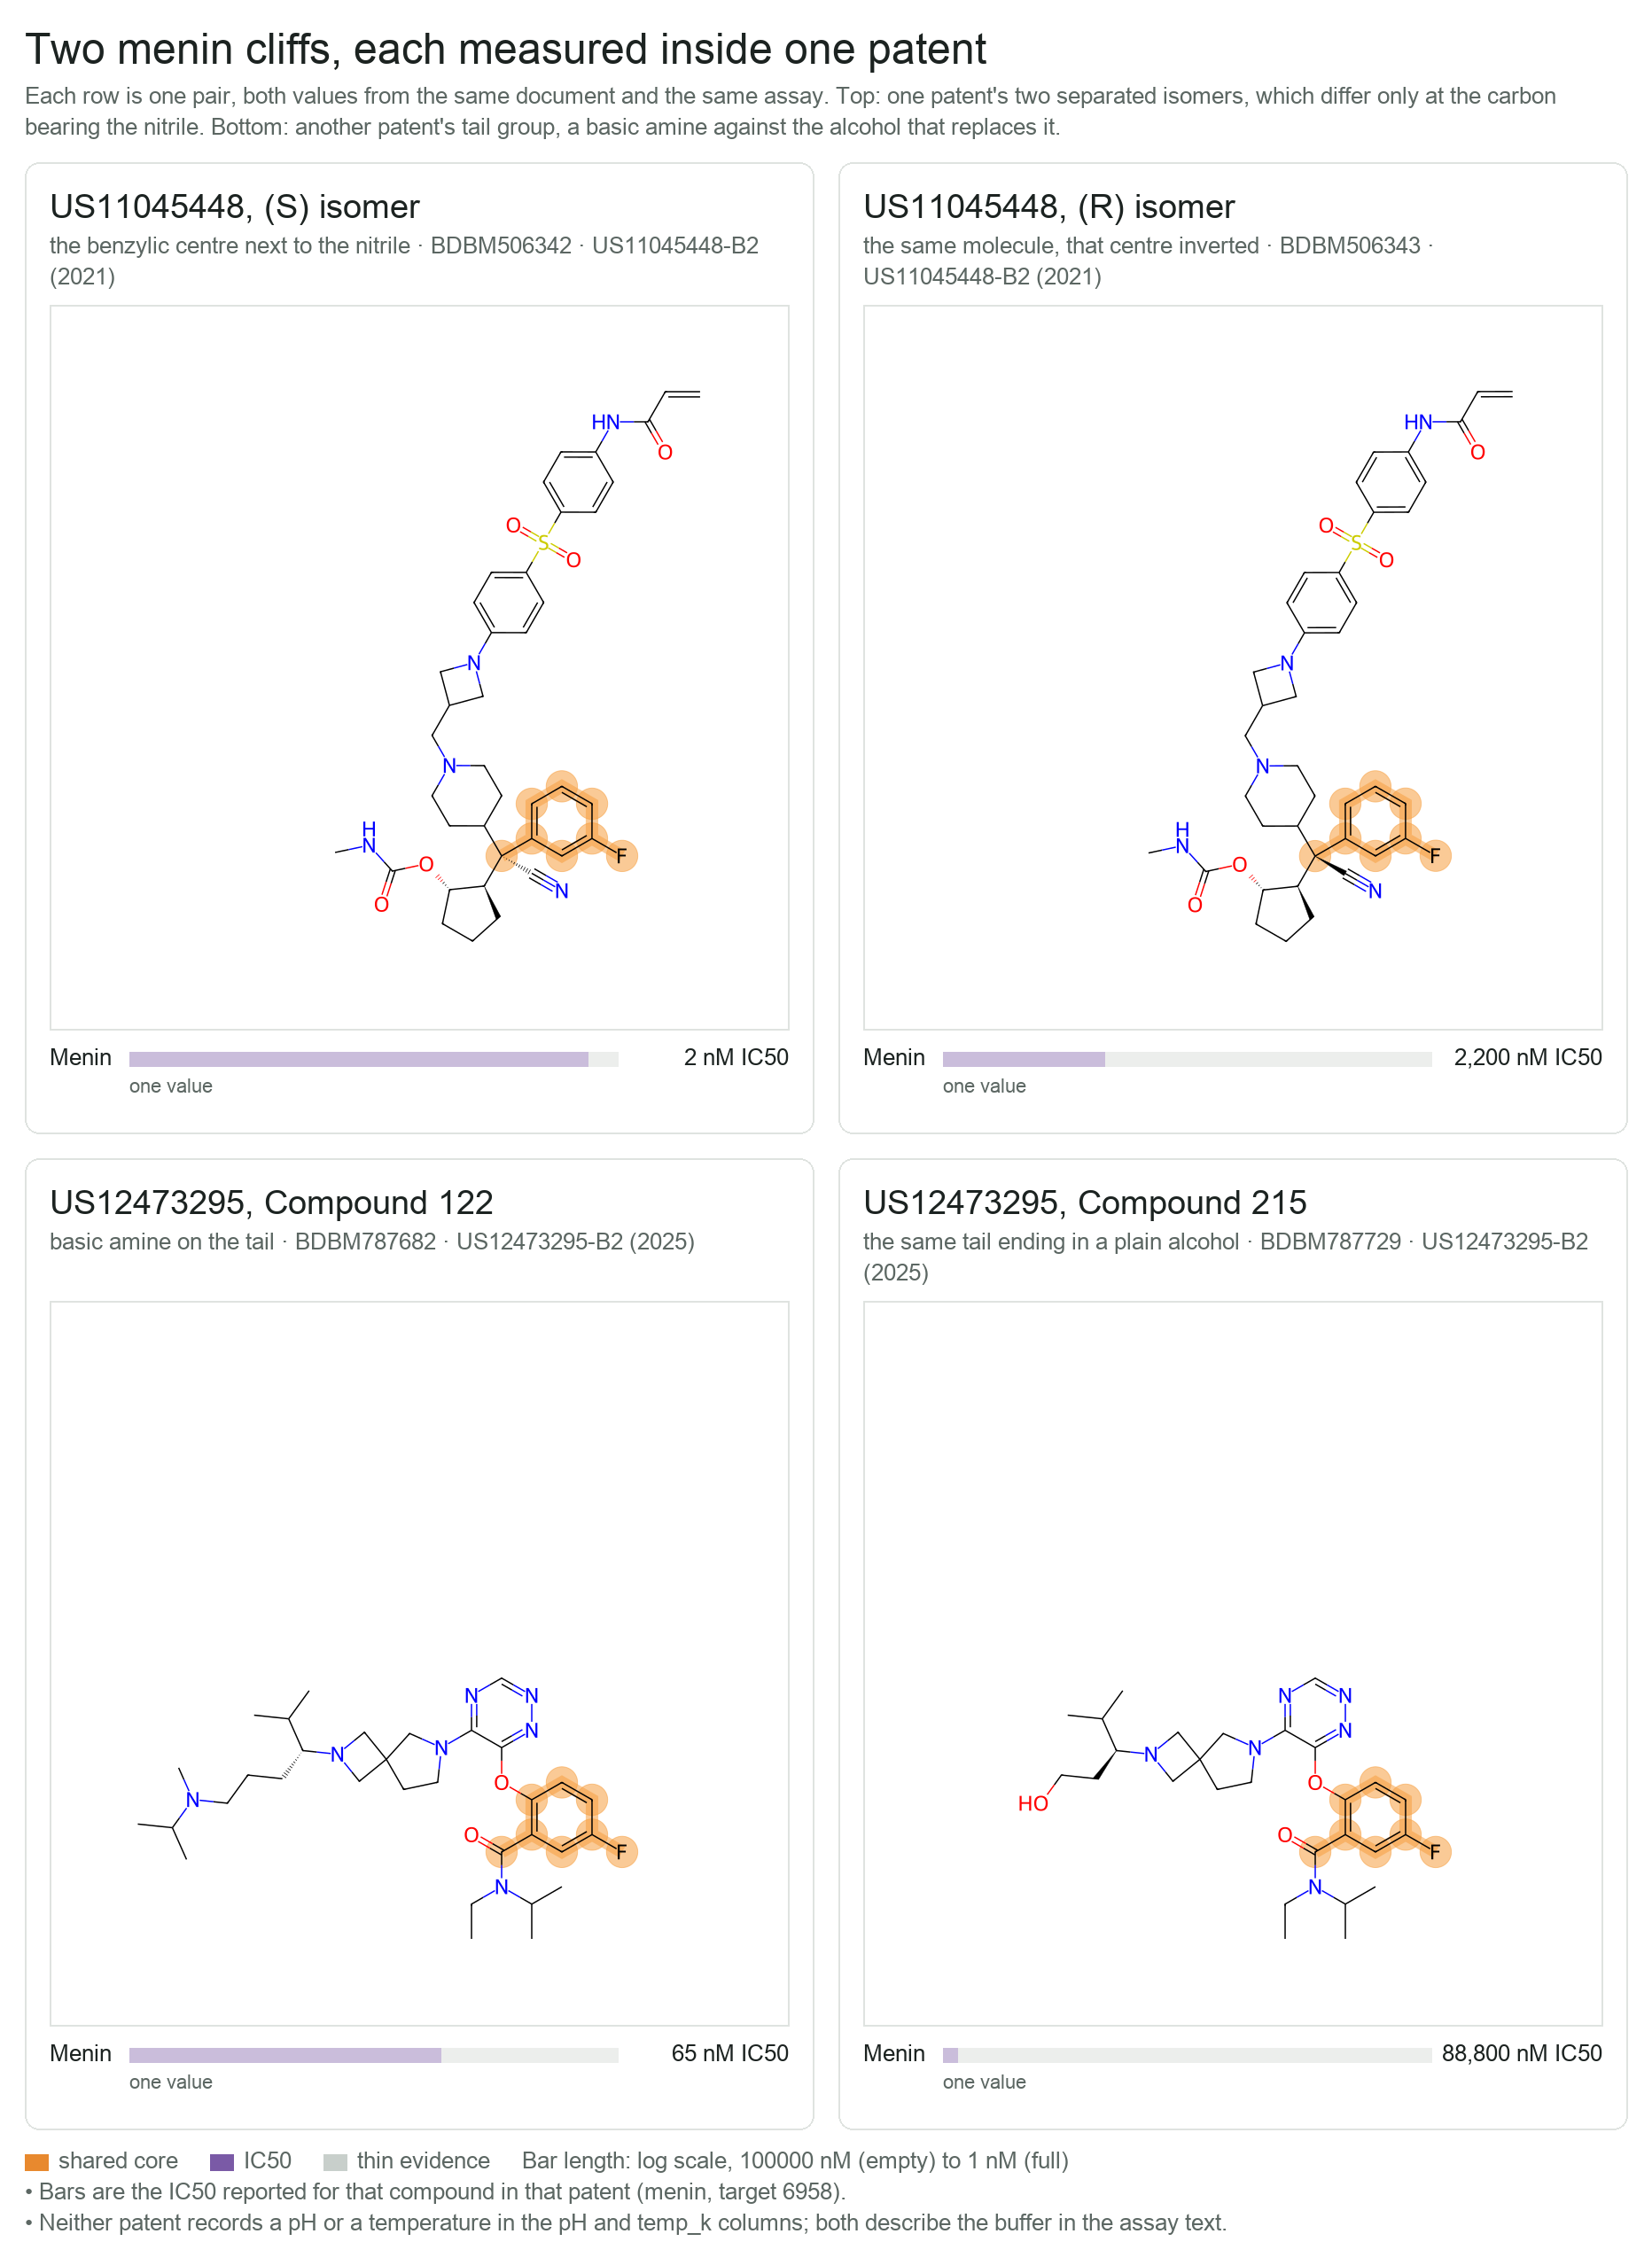

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'Two menin cliffs, each measured inside one patent',
    'compounds': [
        {
            'smiles': 'CNC(=O)O[C@H]1CCC[C@@H]1[C@@](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(NC(=O)C=C)cc2)CC1)c1cccc(F)c1 |r|',
            'title': 'US11045448, (S) isomer',
            'subtitle': 'the benzylic centre next to the nitrile · BDBM506342 · US11045448-B2 (2021)',
            'bars': [{'label': 'Menin', 'value_nm': 2.0, 'type': 'IC50', 'note': 'one value', 'faint': True}],
        },
        {
            'smiles': 'CNC(=O)O[C@H]1CCC[C@@H]1[C@](C#N)(C1CCN(CC2CN(C2)c2ccc(cc2)S(=O)(=O)c2ccc(NC(=O)C=C)cc2)CC1)c1cccc(F)c1 |r|',
            'title': 'US11045448, (R) isomer',
            'subtitle': 'the same molecule, that centre inverted · BDBM506343 · US11045448-B2 (2021)',
            'bars': [
                {'label': 'Menin', 'value_nm': 2200.0, 'type': 'IC50', 'note': 'one value', 'faint': True},
            ],
        },
        {
            'smiles': 'CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN([C@H](CCCN(C)C(C)C)C(C)C)C2)C(C)C',
            'title': 'US12473295, Compound 122',
            'subtitle': 'basic amine on the tail · BDBM787682 · US12473295-B2 (2025)',
            'bars': [{'label': 'Menin', 'value_nm': 65.0, 'type': 'IC50', 'note': 'one value', 'faint': True}],
        },
        {
            'smiles': 'CCN(C(=O)c1cc(F)ccc1Oc1nncnc1N1CCC2(C1)CN([C@@H](CCO)C(C)C)C2)C(C)C',
            'title': 'US12473295, Compound 215',
            'subtitle': 'the same tail ending in a plain alcohol · BDBM787729 · US12473295-B2 (2025)',
            'bars': [
                {
                    'label': 'Menin',
                    'value_nm': 88840.0,
                    'type': 'IC50',
                    'note': 'one value',
                    'faint': True,
                },
            ],
        },
    ],
    'columns': 2,
    'description': "Each row is one pair, both values from the same document and the same assay. Top: one patent's two separated isomers, which differ only at the carbon bearing the nitrile. Bottom: another patent's tail group, a basic amine against the alcohol that replaces it.",
    'notes': [
        'Bars are the IC50 reported for that compound in that patent (menin, target 6958).',
        'Neither patent records a pH or a temperature in the pH and temp_k columns; both describe the buffer in the assay text.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

Among the 928 compounds with an exact IC50 against human menin (target 6958, O00255), activity_cliffs finds **273 pairs** at Tanimoto ≥ 0.85 that differ by at least 100-fold. Reading each pair inside a single document instead of across the database changes the answer substantially:

| After checking the source of both values | Pairs |
|---|---|
| One document reports both compounds, and the gap is still ≥ 100-fold there | 183 |
| One document reports both, but the gap shrinks below 100-fold when read there | 51 |
| No document reports both: the two values come from different places | 39 |

So a third of the list does not survive the rule, and the survivors are not spread evenly: 168 of the 183 sit inside one patent and 15 inside one paper. By document (each pair counted once, under the document where its gap is larger): US12473295-B2 97, US10899738-B2 51, US20240335431-A1 16, US11045448-B2 4, and the papers PMID 23244744 10 and PMID 31244110 5. Two pairs are reported in both US10899738-B2 and PMID 31244110, with a gap of at least 100-fold in each.

**The 90 that were thrown out have a single main cause: 85 of them are one disagreement between two documents of the same patent family.** Three entries are the entire contribution of US20240261292-A1 (2024) to this target: one compound reported at 0.09 and 0.11 nM (measured twice), one named "oxalate" at 0.098 nM, and one at 0.18 nM. Two of the compounds reappear in US12473295-B2 (2025), the first at 80 and 110 nM and the last at 90, 98 and 180 nM, and the "oxalate" entry is a duplicate of the last, its SMILES character-for-character identical. Look at the digits: 0.11 against 110, 0.098 against 98, 0.18 against 180. The 2024 numbers are the 2025 numbers divided by exactly 1,000, and they sit below every one of the 201 compounds' values in the 2025 patent (smallest 33 nM). Both documents give the same written protocol (a terbium-labelled menin / FITC-peptide HTRF competition), so nothing in the recorded conditions explains a gap of 500 to 1,000-fold, and a unit slip in one document is the likelier explanation than biology. That is an inference from the pattern, not something the database states: the raw values are recorded as 0.110, 0.090, 0.098 and 0.180 with the unit nM. Either way the rule is right to refuse the comparison. Of the other 5 discarded pairs, 4 pair a PMID 31244110 value with a US10899738-B2 one that has no document in common, and one is 95 against 9,450 nM inside US12473295-B2, 99.5-fold, just under the threshold.

**Why the rule is not the same as what the tool reports.** activity_cliffs ranks each compound by its most potent exact value anywhere in the database, which is the right default, but it means the two halves of a pair can come from two different labs. Here that is not a hypothetical: the pair at the top of the raw output is 28,000-fold (0.098 nM against 2,750 nM) and its two values come from two different patents, the 2024 one and the 2025 one. The check is one SQL query: list every (compound, source) value for the compounds in the cliff list, keep the pairs with a source in common, and recompute the difference from that source's own two numbers.

**What the conditions say.** For the two pairs in the figure the check is clean, and it is worth being precise about what "checked" means here:
- Both values of each pair carry the same assay_name, because each pair sits in one patent and each of these patents reports everything under one assay.
- The ph and temp_k columns are empty, for all 988 menin exact IC50 rows (20 documents), not just these.
- The conditions are nonetheless recorded, in the assay table's protocol text: US12473295-B2 runs a terbium-labelled menin / FITC-MBM1 peptide HTRF competition in 40 mM Tris·HCl pH 7.5, 50 mM NaCl, 1 mM DTT, 0.05% Pluronic F-127, 30 minutes of compound with menin at ambient temperature and then 15 more with the peptide; US11045448-B2 runs a fluorescence polarisation competition with a FAM-labelled MLL1 peptide in PBS with 0.02% bovine γ-globulin, 4% DMSO and 0.01% Triton X-100, 30 minutes at room temperature. Different formats, which is exactly why a cliff should not straddle them.

**The survivors, and what they are made of.** 40 of the 183 have identical fingerprints (sali is null because the structural distance is zero), and on this target that almost always means a configuration: 16 of them in US10899738-B2, 12 in US20240335431-A1, 10 in US12473295-B2, 2 in US11045448-B2. The rest are small constitutional changes. The figure shows one of each kind. Its four compounds come from two different chemotypes, so the grid's alignment is on the 8-atom fragment they all share (a fluorophenyl and the carbon on it), not on a real common core; read each pair on its own.
- **A separated pair of isomers**, 2 nM against 2,200 nM in US11045448-B2: same molecule, same assay, same table, inverted at the carbon that carries the nitrile. A 1,100-fold eutomer/distomer ratio is real SAR and is the kind of cliff worth having.
- **A tail group**, 65 nM against 88,840 nM in US12473295-B2: the basic amine at the end of the chain replaced by a short alcohol, 1,400-fold. The length-matched version of that swap is in the same patent: its 3-hydroxypropyl analogue is 70,390 nM, so the result is not an artefact of the shorter chain. On this chemotype the basic nitrogen is worth about three logs.

US10899738-B2 makes the stereochemical point repeatedly: its cyclopentyl esters come as a pair of enantiomers, labelled rac-(1S,2R) and rac-(1R,2S), and in the two series I read the first is 700 to 1,100-fold the more potent: 13 against 13,800 nM for the acetate, 237 against 164,600 nM for the isobutyrate.

**Two things the rule does not fix.** First, nearly every value here is a single measurement (both sides single in 173 of the 183 pairs), so "same patent" removes the cross-lab problem but not a single mistyped number, and the 2024 patent just showed what one looks like. Second, the largest surviving cliff, 16 nM against 923,130 nM in US10899738-B2 (57,000-fold), changes two things at once, the aryl group (3-fluorophenyl to 3-trifluoromethylphenyl) as well as the configuration, so it is not a clean one-change pair however well measured it is. Cliffs at the top of a list are worth reading individually before they are worth believing.

**How this was answered**
- search_targets for "menin" in Homo sapiens gave target 6958 (O00255, 1,073 compounds); the tool picked IC50, its most measured exact type.
- activity_cliffs with min_similarity: 0.85, min_delta_p: 2.0 and max_compounds: 2000 returned all 273 pairs, each with both compounds' ids and best values.
- run_sql listed every (compound, source_id) value for the 213 compounds appearing in those pairs; a pair was kept only where one source_id reports both, and the difference was recomputed from that source's two values (the code cell below).
- Further run_sql queries read the 2024 patent's four values against the 2025 patent's, and assay_name, ph and temp_k for the figure's four compounds, and joined activity to the assay table on entryid for the protocol text behind each patent.

**Try next**
- "How much does BindingDB actually record about the conditions?" (the follow-up below)
- "Show me the cliffs inside US10899738-B2 only" (the same call, then filter to that source)

Example 4.2 is the other way of reading the same data: one substituent change at a time, aggregated over a whole target.

## Exchange 2

**👤 User**

How much does BindingDB actually record about the conditions? Can I always do this?

In [ ]:
# Call 15 · run_sql · ran 2026-11-24 04:55:28 UTC
sql = """
    SELECT CASE WHEN regexp_matches(source_id, '^[0-9]+$') THEN 'article (PMID)' WHEN regexp_matches(source_id, '^aid[0-9]+$') THEN 'PubChem assay' WHEN regexp_matches(source_id, '^D3R') THEN 'D3R challenge' ELSE 'patent' END AS kind, count(*) AS n_values, count(DISTINCT source_id) AS n_sources, round(100.0 * count(ph) / count(*), 1) AS pct_ph, round(100.0 * count(temp_k) / count(*), 1) AS pct_temp, round(100.0 * count(assay_name) / count(*), 1) AS pct_assay_name FROM activity WHERE affinity_type IN ('Ki','Kd','IC50','EC50') AND relation = '=' AND value IS NOT NULL GROUP BY kind ORDER BY n_values DESC, kind
    
"""
await replay.call(15, 'run_sql', {'sql': sql, 'limit': 10},
                  sha256='7303625c16a3b013cea0107a29f0a2315052930d1a129d1ac4609eb78c1ded1d')

**Call 15** · `run_sql` · recorded result · sha256 `7303625c16a3…`

_4 rows_

| kind | n_values | n_sources | pct_ph | pct_temp | pct_assay_name |
| --- | --- | --- | --- | --- | --- |
| article (PMID) | 1454575 | 45157 | 2.9 | 2.6 | 98.4 |
| patent | 1062387 | 8680 | 13 | 12.2 | 99 |
| PubChem assay | 72558 | 663 | 3.8 | 5.8 | 92.9 |
| D3R challenge | 2659 | 24 | 3.5 | 0 | 100 |


In [ ]:
# Call 16 · run_sql · ran 2026-11-24 04:55:28 UTC
sql = """
    WITH p AS (SELECT source_id, count(DISTINCT assay_name) AS n_names, count(*) AS n_values FROM activity WHERE affinity_type IN ('Ki','Kd','IC50','EC50') AND relation = '=' AND value IS NOT NULL AND NOT regexp_matches(source_id, '^([0-9]+|aid[0-9]+|D3R.*)$') GROUP BY source_id) SELECT n_names, count(*) AS n_patents, sum(n_values) AS n_values FROM p GROUP BY n_names ORDER BY n_names
    
"""
await replay.call(16, 'run_sql', {'sql': sql, 'limit': 30},
                  sha256='8ab41ceede35f564f6fded246de53cca80b5e3f512833344430ccb95d44191c9')

**Call 16** · `run_sql` · recorded result · sha256 `8ab41ceede35…`

_10 rows_

| n_names | n_patents | n_values |
| --- | --- | --- |
| 0 | 14 | 1036 |
| 1 | 6970 | 737832 |
| 2 | 1255 | 206540 |
| 3 | 272 | 50472 |
| 4 | 106 | 20811 |
| 5 | 30 | 5394 |
| 6 | 16 | 4970 |
| 7 | 12 | 2563 |
| 8 | 4 | 1288 |
| 10 | 1 | 33 |


In [ ]:
# Call 17 · run_sql · ran 2026-11-24 04:55:28 UTC
sql = """
    SELECT source_id, count(*) AS n_values, count(DISTINCT assay_name) AS n_assay_names, min(assay_name) AS assay_name FROM activity WHERE polymerid = 6958 AND affinity_type = 'IC50' AND relation = '=' GROUP BY source_id ORDER BY n_values DESC, source_id
    
"""
await replay.call(17, 'run_sql', {'sql': sql, 'limit': 30},
                  sha256='dbae6992198ff50b8df7040ecf3a6af48c402f4747394ce6e5d80418c8cb60a8')

**Call 17** · `run_sql` · recorded result · sha256 `dbae6992198f…`

_20 rows_

| source_id | n_values | n_assay_names | assay_name |
| --- | --- | --- | --- |
| US10899738-B2 | 386 | 1 | Fluorescence Polarization (FP) Competitive Binding Assay |
| US12473295-B2 | 204 | 1 | Menin/MLL Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| US20240335431-A1 | 78 | 1 | Fluorescence Polarization (FP) Assay |
| US8993552-B2 | 72 | 3 | Fluorescence Polarization Assay |
| 31244110 | 39 | 2 | ChEMBL\_1865912 (CHEMBL4366887) |
| US11045448-B2 | 37 | 1 | Menin Binding Affinity |
| 23244744 | 34 | 1 | ChEMBL\_934332 (CHEMBL2320318) |
| 29738674 | 29 | 1 | ChEMBL\_1755017 (CHEMBL4189777) |
| 24472025 | 28 | 1 | ChEMBL\_1298276 (CHEMBL3130541) |
| 34196551 | 20 | 1 | ChEMBL\_2155531 (CHEMBL5040191) |
| 32338903 | 15 | 2 | ChEMBL\_1846020 (CHEMBL4346447) |
| 38367493 | 12 | 2 | ChEMBL\_2428620 |
| 26288158 | 9 | 1 | ChEMBL\_1515211 (CHEMBL3614558) |
| 29795748 | 9 | 1 | ChEMBL\_1734172 (CHEMBL4149708) |
| 29254892 | 7 | 3 | ChEMBL\_1752090 (CHEMBL4186850) |
| US20240261292-A1 | 4 | 1 | Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| US20250197392-A1 | 2 | 1 | Menin/MLL Homogenous Time-Resolved Fluorescence (HTRF) Assay |
| 29775308 | 1 | 1 | ChEBML\_1734065 |
| 34726905 | 1 | 1 | ChEMBL\_2269168 |
| 39366253 | 1 | 1 | ChEMBL\_2616495 |


**🧠 Assistant**

Enough to do this on most targets, as long as you accept that "the conditions" usually means a block of prose rather than two numeric columns. Over every exact Ki, Kd, IC50 and EC50 value in nM:

| Source | Values | Sources | pH recorded | Temperature recorded | Assay name |
|---|---|---|---|---|---|
| Article (PMID) | 1,454,575 | 45,157 | 2.9% | 2.6% | 98.4% |
| Patent | 1,062,387 | 8,680 | 13.0% | 12.2% | 99.0% |
| PubChem assay | 72,558 | 663 | 3.8% | 5.8% | 92.9% |
| D3R challenge set | 2,659 | 24 | 3.5% | 0.0% | 100% |

**So the numeric columns are the exception.** ph and temp_k are populated for roughly one value in eight from patents and one in thirty-five from papers, and, against intuition, patents are the better-curated source for them, not the worse. On menin they are empty for all 988 rows, which is why the previous answer leaned on the assay text instead: US12473295-B2 states pH 7.5 in its protocol, and that pH never reaches the ph column.

**What is almost always there is assay_name**, on 98 to 99% of values, and behind it the assay table, keyed by entryid, which carries the full protocol paragraph: buffer, probe, peptide, incubation, plate format, often the temperature in words ("ambient"). That is the layer to read when a comparison matters. activity joins to it on entryid, and one query per document is enough.

**"Same patent" is a good proxy for "same assay", but not a perfect one.** Of the 8,680 patents with exact values, 6,970 report everything under a single assay name; 1,255 use two, 272 three, 106 four, 30 five, 33 use six or more, and 14 have none recorded. So about one patent in five mixes formats, typically a biochemical assay and a cell assay in the same document, whose IC50s belong in different columns entirely. The robust rule is therefore two conditions, not one: same source_id and same assay_name. On menin that distinction changes nothing for the patents behind the answer above: US12473295-B2, US10899738-B2, US20240335431-A1 and US11045448-B2 each use one assay name. One of the two papers does not: PMID 31244110 reports two assay names on menin, but the nine compounds in its five surviving pairs were all measured under the same one, so those pairs stand. On a patent with a biochemical and a cellular readout the second condition would change everything.

**What this never gives you, on any target.** The same patent is not the same plate, the same day or the same protein batch: a patent's table is often assembled over several years of a programme. And a document reporting one assay name can still report values measured in two different laboratories. Within-document comparison removes the largest and most systematic source of noise; it does not turn a database into a single experiment.

**A practical order to check things in, cheapest first:**
1. source_id: do both numbers come from one document at all? (One SQL query, as in the first answer.)
2. assay_name: is it the same assay within that document?
3. The assay table's description: what was actually done, and does the text name a pH, a temperature, a probe concentration?
4. ph and temp_k: use them when present; do not design a workflow that depends on them.
5. The number of measurements behind each side: n_measurements in the SAR tools, or get_activity for the individual rows. A cliff where both sides are single values is a hypothesis, however well sourced.

**How this was answered**
- run_sql grouped every exact Ki/Kd/IC50/EC50 value in nM by the kind of source its source_id denotes, counting how often ph, temp_k and assay_name are populated.
- run_sql counted distinct assay_name values per patent, over all patents with exact measurements, and per document on menin.
- The menin figure in the previous answer came from the same two tables: activity for the values and their assay_name, the assay table for the protocol text behind each entryid.

**Try next**
- "Show me the full protocol for US12473295-B2" (the assay table's description, untruncated)
- "Which of this target's patents report more than one assay name?" (the check that makes the rule safe)

Example 3.4 drills into a single measurement end to end: value, assay, conditions, citation.

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 17 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 4.3 — Activity cliffs: only the ones measured in the same patent, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```